# Notebook 07 — US COVID-19 Data Analysis

**Objective:** Explore and characterise the NYT US COVID-19 time series
(2020-01-21 → 2023-03-23) with **data analysis only** — no modelling.
We load the data, verify its internal consistency, and describe the
pandemic through figures, tables and descriptive statistics.

| Section | Content |
|---------|---------|
| 7.1 | Data loading & full-pandemic overview |
| 7.2 | Data quality check: national vs state consistency |
| 7.3 | Wave segmentation & descriptive statistics |
| 7.4 | State-level analysis: per-state overview & summary |
| 7.5 | BTS aviation mobility data |

**Data source:** New York Times COVID-19 Data Repository
<https://github.com/nytimes/covid-19-data>
(archived, last update 2023-03-23)


In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from data_loader import (
    load_us_national, load_us_states,
    get_wave, wave_summary, US_WAVES, US_POPULATION
)

# ── figure style ──────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 11,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3,
})

WAVE_COLORS = ['#e41a1c','#ff7f00','#4daf4a','#984ea3','#377eb8']
print("Imports OK")

Imports OK


In [2]:
# Load national data
df = load_us_national()
print(f"Records: {len(df)}  |  {df.date.min().date()} → {df.date.max().date()}")
print(f"Cumulative peak cases : {df.cum_cases.iloc[-1]/1e6:.1f}M")
print(f"Cumulative peak deaths: {df.cum_deaths.iloc[-1]/1e3:.0f}k")
df.head(10)

Records: 1158  |  2020-01-21 → 2023-03-23
Cumulative peak cases : 103.9M
Cumulative peak deaths: 1135k


,date,cum_cases,cum_deaths,new_cases,new_deaths,new_cases_smooth,new_deaths_smooth,active_cases,N
0,2020-01-21,1,0,0.0,0.0,0.250000,0.0,0.0,331449281
1,2020-01-22,1,0,0.0,0.0,0.400000,0.0,0.0,331449281
2,2020-01-23,1,0,0.0,0.0,0.666667,0.0,0.0,331449281
3,2020-01-24,2,0,1.0,0.0,0.571429,0.0,1.0,331449281
4,2020-01-25,3,0,1.0,0.0,0.571429,0.0,2.0,331449281
5,2020-01-26,5,0,2.0,0.0,0.571429,0.0,4.0,331449281
6,2020-01-27,5,0,0.0,0.0,0.714286,0.0,4.0,331449281
7,2020-01-28,5,0,0.0,0.0,0.714286,0.0,4.0,331449281
8,2020-01-29,5,0,0.0,0.0,0.714286,0.0,4.0,331449281
9,2020-01-30,6,0,1.0,0.0,0.857143,0.0,5.0,331449281


## 7.1 — Data Loading & Full-Pandemic Overview

We plot:
- **Cumulative confirmed cases** and **cumulative deaths** (separate panels)
- **Daily new cases** (7-day average) with wave annotations

**A note on scale:** at the end of the series cumulative deaths (≈ 1.14 M) are
only ≈ 1 % of cumulative cases (≈ 103.9 M).  Plotting both series on
*auto-scaled twin axes* of the same panel (millions vs thousands) makes the
death curve appear *above* the case curve — a purely visual artefact of the two
different y-scales, not of the data (the numbers are verified in §7.2).
To avoid this misleading effect, the two cumulative series are plotted on
**separate panels** here.


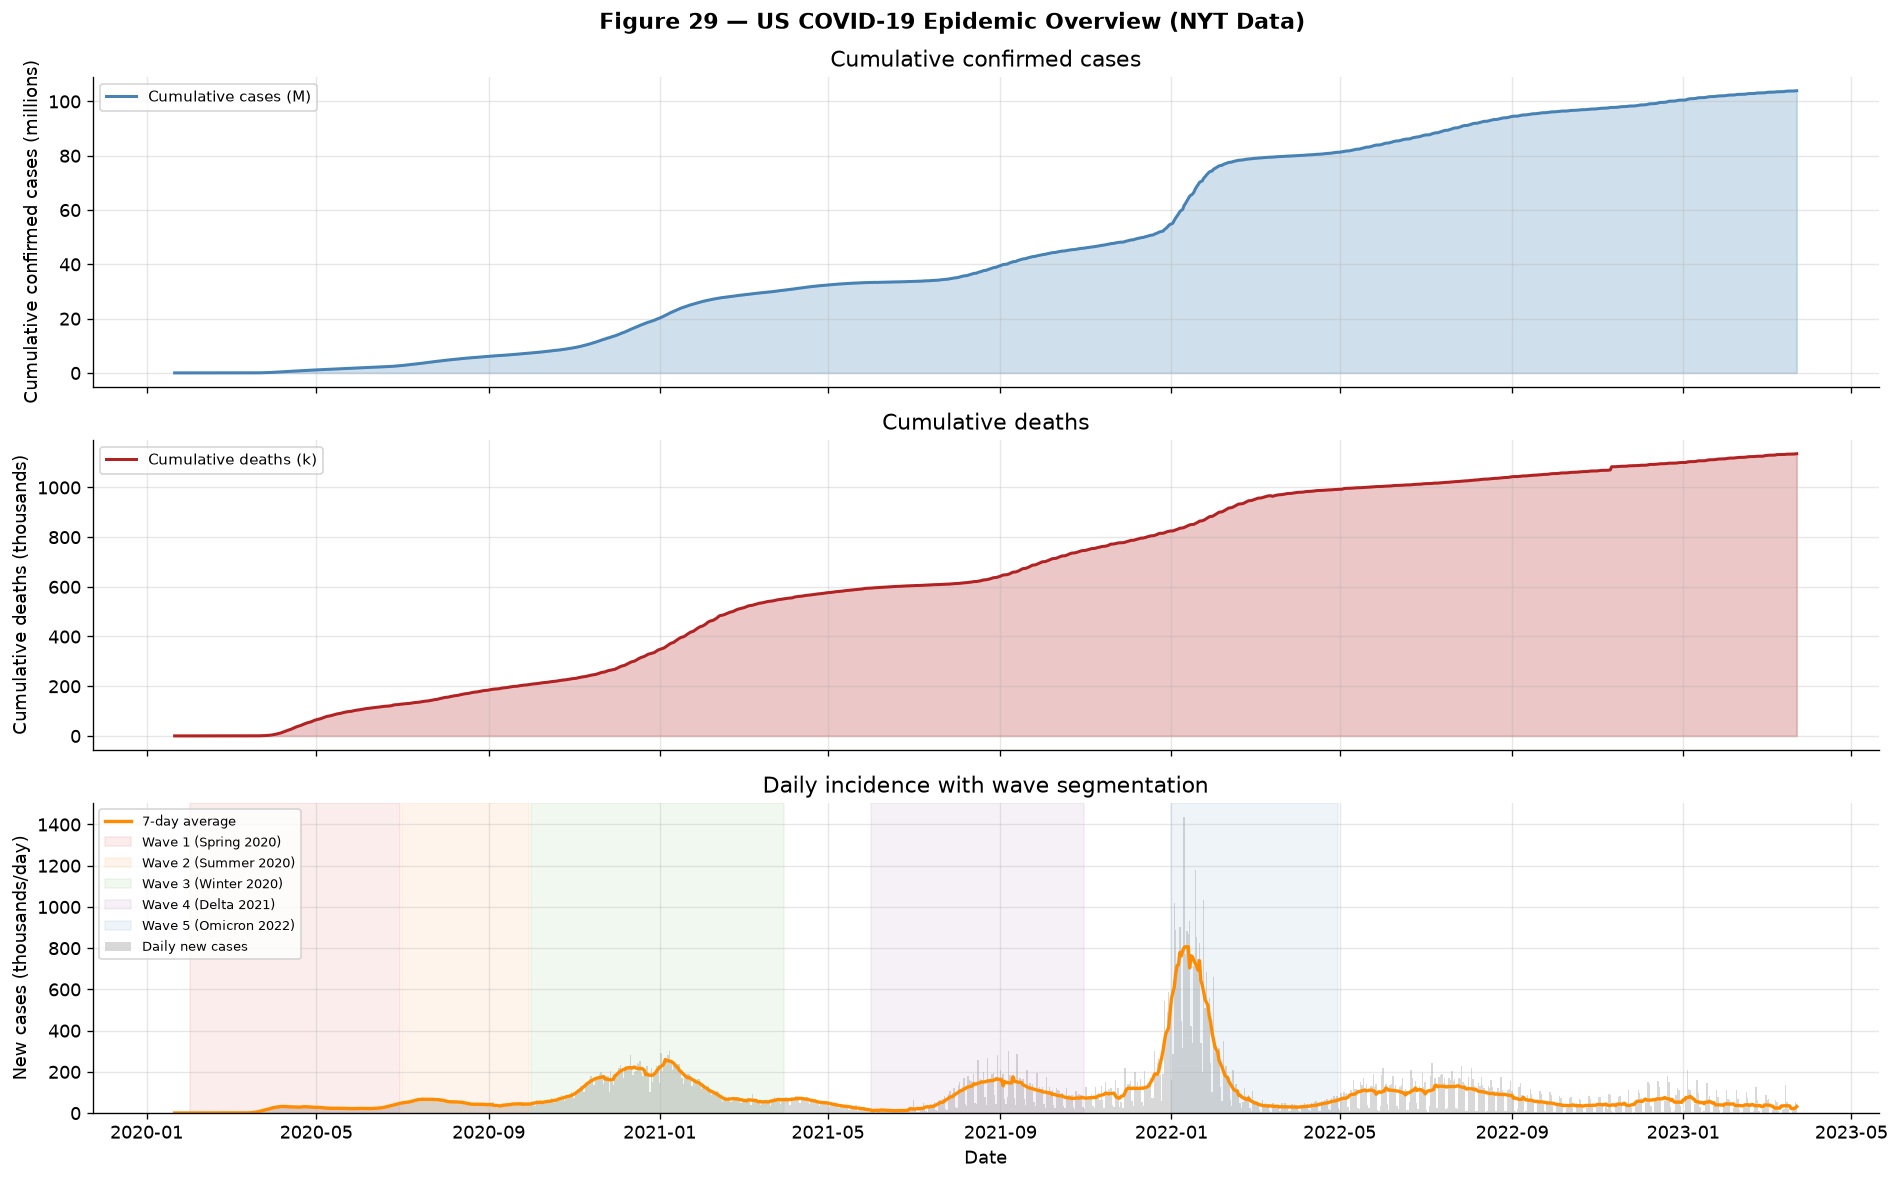

Figure 29 saved.


In [3]:
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
fig.suptitle('Figure 29 — US COVID-19 Epidemic Overview (NYT Data)',
             fontsize=13, fontweight='bold')

# ── top: cumulative confirmed cases ───────────────────────────────────────────
ax1 = axes[0]
ax1.fill_between(df.date, df.cum_cases/1e6, alpha=0.25, color='steelblue')
ax1.plot(df.date, df.cum_cases/1e6, color='steelblue', lw=1.8,
         label='Cumulative cases (M)')
ax1.set_ylabel('Cumulative confirmed cases (millions)')
ax1.set_title('Cumulative confirmed cases')
ax1.legend(loc='upper left', fontsize=9)

# ── middle: cumulative deaths ─────────────────────────────────────────────────
ax2 = axes[1]
ax2.fill_between(df.date, df.cum_deaths/1e3, alpha=0.25, color='firebrick')
ax2.plot(df.date, df.cum_deaths/1e3, color='firebrick', lw=1.8,
         label='Cumulative deaths (k)')
ax2.set_ylabel('Cumulative deaths (thousands)')
ax2.set_title('Cumulative deaths')
ax2.legend(loc='upper left', fontsize=9)

# ── bottom: daily new cases with wave segmentation ────────────────────────────
ax3 = axes[2]
ax3.bar(df.date, df.new_cases/1e3, width=1, alpha=0.3, color='gray',
        label='Daily new cases')
ax3.plot(df.date, df.new_cases_smooth/1e3, color='darkorange', lw=2,
         label='7-day average')

for i, (wname, (ws, we)) in enumerate(US_WAVES.items()):
    ax3.axvspan(pd.Timestamp(ws), pd.Timestamp(we),
                alpha=0.08, color=WAVE_COLORS[i], label=wname)

ax3.set_ylabel('New cases (thousands/day)')
ax3.set_xlabel('Date')
ax3.set_title('Daily incidence with wave segmentation')
ax3.legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.savefig('../assets/fig29_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 29 saved.")

## 7.2 — Data Quality Check: National vs State Consistency

Two data files are provided:
- `data/nyt_us_national.csv` — national daily cumulative cases & deaths
- `data/nyt_us_states.csv` — the same series per state / territory

A basic sanity check: **the national total should equal the sum over all
state-level rows for every date** (the NYT national file is derived from the
state file).  We additionally check:
1. whether the US territories (Puerto Rico, Guam, Virgin Islands, Northern
   Mariana Islands), which appear in the state file, are included in the
   national totals;
2. whether the cumulative series ever *decreases* day-over-day (downward
   revisions in the source data).


In [4]:
# ── national vs sum of all state/territory rows ──────────────────────────────
nat = load_us_national(smooth=False)
st  = load_us_states(smooth=False)

sum_all = st.groupby('date')[['cum_cases', 'cum_deaths']].sum()
sum_all.columns = ['cases_sum', 'deaths_sum']
chk = nat.merge(sum_all, left_on='date', right_index=True)

d_cases  = (chk['cases_sum']  - chk['cum_cases']).abs()
d_deaths = (chk['deaths_sum'] - chk['cum_deaths']).abs()

print(f"Dates compared: {len(chk)}   ({chk.date.min().date()} → {chk.date.max().date()})")
print(f"Cases  : max |sum − national| = {d_cases.max():,}"
      f"   mean = {d_cases.mean():,.2f}")
print(f"Deaths : max |sum − national| = {d_deaths.max():,}"
      f"   mean = {d_deaths.mean():,.2f}")
print(f"\nFinal totals  —  national: cases {chk.cum_cases.iloc[-1]:,}, "
      f"deaths {chk.cum_deaths.iloc[-1]:,}")
print(f"                 sum:      cases {chk.cases_sum.iloc[-1]:,}, "
      f"deaths {chk.deaths_sum.iloc[-1]:,}")

if (d_cases.max() == 0 and d_deaths.max() == 0):
    print("\n✓ National file is EXACTLY the sum of the state file "
          "(incl. territories) on every date.")
else:
    worst = chk.assign(diff=d_cases).nlargest(5, 'diff')
    print("\n✗ Discrepancy found — worst 5 dates (cases diff):")
    for _, r in worst.iterrows():
        print(f"    {r.date.date()}: sum={r.cases_sum:,} nat={r.cum_cases:,}"
              f" diff={r.diff:+,}")

# ── territories present in the state file ─────────────────────────────────────
TERR = ['Puerto Rico', 'Guam', 'Virgin Islands', 'Northern Mariana Islands']
terr_cases = st[st['state'].isin(TERR)].groupby('state')['cum_cases'].max()
print("\nTerritories present in the state file (final cumulative cases):")
for name, v in terr_cases.items():
    print(f"  {name:24s} {v:>12,}")
print(f"  {'Sum of territories':24s} {terr_cases.sum():>12,}")

# ── negative daily changes (downward revisions) ───────────────────────────────
nc = nat['cum_cases'].diff()
nd = nat['cum_deaths'].diff()
print("\nNegative daily changes in the national series (data revisions):")
print(f"  cases : {int((nc < 0).sum())} day(s), largest −{int(-nc.min()):,} "
      f"on {nat.loc[nc.idxmin(), 'date'].date()}")
print(f"  deaths: {int((nd < 0).sum())} day(s), largest −{int(-nd.min()):,} "
      f"on {nat.loc[nd.idxmin(), 'date'].date()}")

Dates compared: 1158   (2020-01-21 → 2023-03-23)
Cases  : max |sum − national| = 0   mean = 0.00
Deaths : max |sum − national| = 0   mean = 0.00

Final totals  —  national: cases 103,910,034, deaths 1,135,343
                 sum:      cases 103,910,034, deaths 1,135,343

✓ National file is EXACTLY the sum of the state file (incl. territories) on every date.

Territories present in the state file (final cumulative cases):
  Guam                           62,077
  Northern Mariana Islands       13,395
  Puerto Rico                 1,139,243
  Virgin Islands                 24,838
  Sum of territories          1,239,553

Negative daily changes in the national series (data revisions):
  cases : 3 day(s), largest −23,999 on 2021-06-04
  deaths: 3 day(s), largest −2,435 on 2022-03-14


## 7.3 — Wave Segmentation & Descriptive Statistics

The US pandemic unfolded in a sequence of distinct **waves**, driven by
successive variants, seasonality and changing interventions.  We segment the
series into five major waves (the same scheme used across this project):

| Wave | Period | Dominant variant |
|------|--------|------------------|
| 1 | Feb–Jun 2020 | Original (D614G) |
| 2 | Jul–Sep 2020 | Original |
| 3 | Oct 2020 – Mar 2021 | Alpha (dominant from ~Apr 2021) |
| 4 | Jun–Oct 2021 | **Delta** (dominant from ~Jul 2021) |
| 5 | Jan–Apr 2022 | **Omicron** BA.1/BA.2 |

### Where this segmentation comes from

There is no single *official* wave definition, but this scheme matches the
documented milestones of the pandemic (Wikipedia timeline of the US pandemic;
CDC variant-proportion data):

- **Wave 1 (Spring 2020):** first wave, peaking ~mid-April 2020.
- **Wave 2 (Summer 2020):** a second wave began in June 2020 after
  reopenings, peaking ~July 2020.
- **Wave 3 (Fall/Winter 2020–21):** third surge from mid-October 2020,
  peaking ~January 2021; Alpha became the dominant strain ~April 2021.
- **Wave 4 (Delta):** Delta became dominant ~July 2021 and accounted for
  ~99 % of US cases by August 2021; the national peak was ~September 2021.
- **Wave 5 (Omicron):** Omicron emerged ~December 2021; record case counts
  peaked ~January 2022, with BA.2 continuing into the spring.

### The gaps between segments are real inter-wave troughs

The five windows are not contiguous on purpose:

- **Apr–May 2021** (between W3 and W4): a genuine lull — cases fell steeply
  after the winter surge as vaccination rolled out, before Delta took off.
- **Nov–Dec 2021** (between W4 and W5): Delta declined to a low baseline in
  November 2021 before the Omicron surge began in December 2021.

### Notes on the covered period

- The data span **2020-01-21 → 2023-03-23**; the 5-wave scheme ends in
  April 2022.  Later activity (BA.2/BA.5 in 2022, the XBB winter wave of
  2022–23) is outside the scope of this segmentation.
- Within the W1 window, the smoothed daily series reaches its maximum on the
  *last day* of the window (2020-06-30), because the summer surge starts
  immediately after the spring wave; the true spring peak (~mid-April 2020)
  is lower.  This boundary effect is visible in the statistics below.


  Date range  : 2020-02-01 → 2020-06-30
  Total cases : 2,653,313
  Total deaths: 127,462
  Peak date   : 2020-06-30  (47,482 new cases/day)
  CFR (approx): 4.80%
  Date range  : 2020-07-01 → 2020-09-30
  Total cases : 4,559,439
  Total deaths: 78,748
  Peak date   : 2020-07-22  (66,783 new cases/day)
  CFR (approx): 1.73%
  Date range  : 2020-10-01 → 2021-03-31
  Total cases : 23,169,733
  Total deaths: 343,962
  Peak date   : 2021-01-05  (259,616 new cases/day)
  CFR (approx): 1.48%
  Date range  : 2021-06-01 → 2021-10-31
  Total cases : 12,633,616
  Total deaths: 150,902
  Peak date   : 2021-09-10  (175,822 new cases/day)
  CFR (approx): 1.19%
  Date range  : 2022-01-01 → 2022-04-30
  Total cases : 26,408,606
  Total deaths: 167,401
  Peak date   : 2022-01-11  (806,927 new cases/day)
  CFR (approx): 0.63%


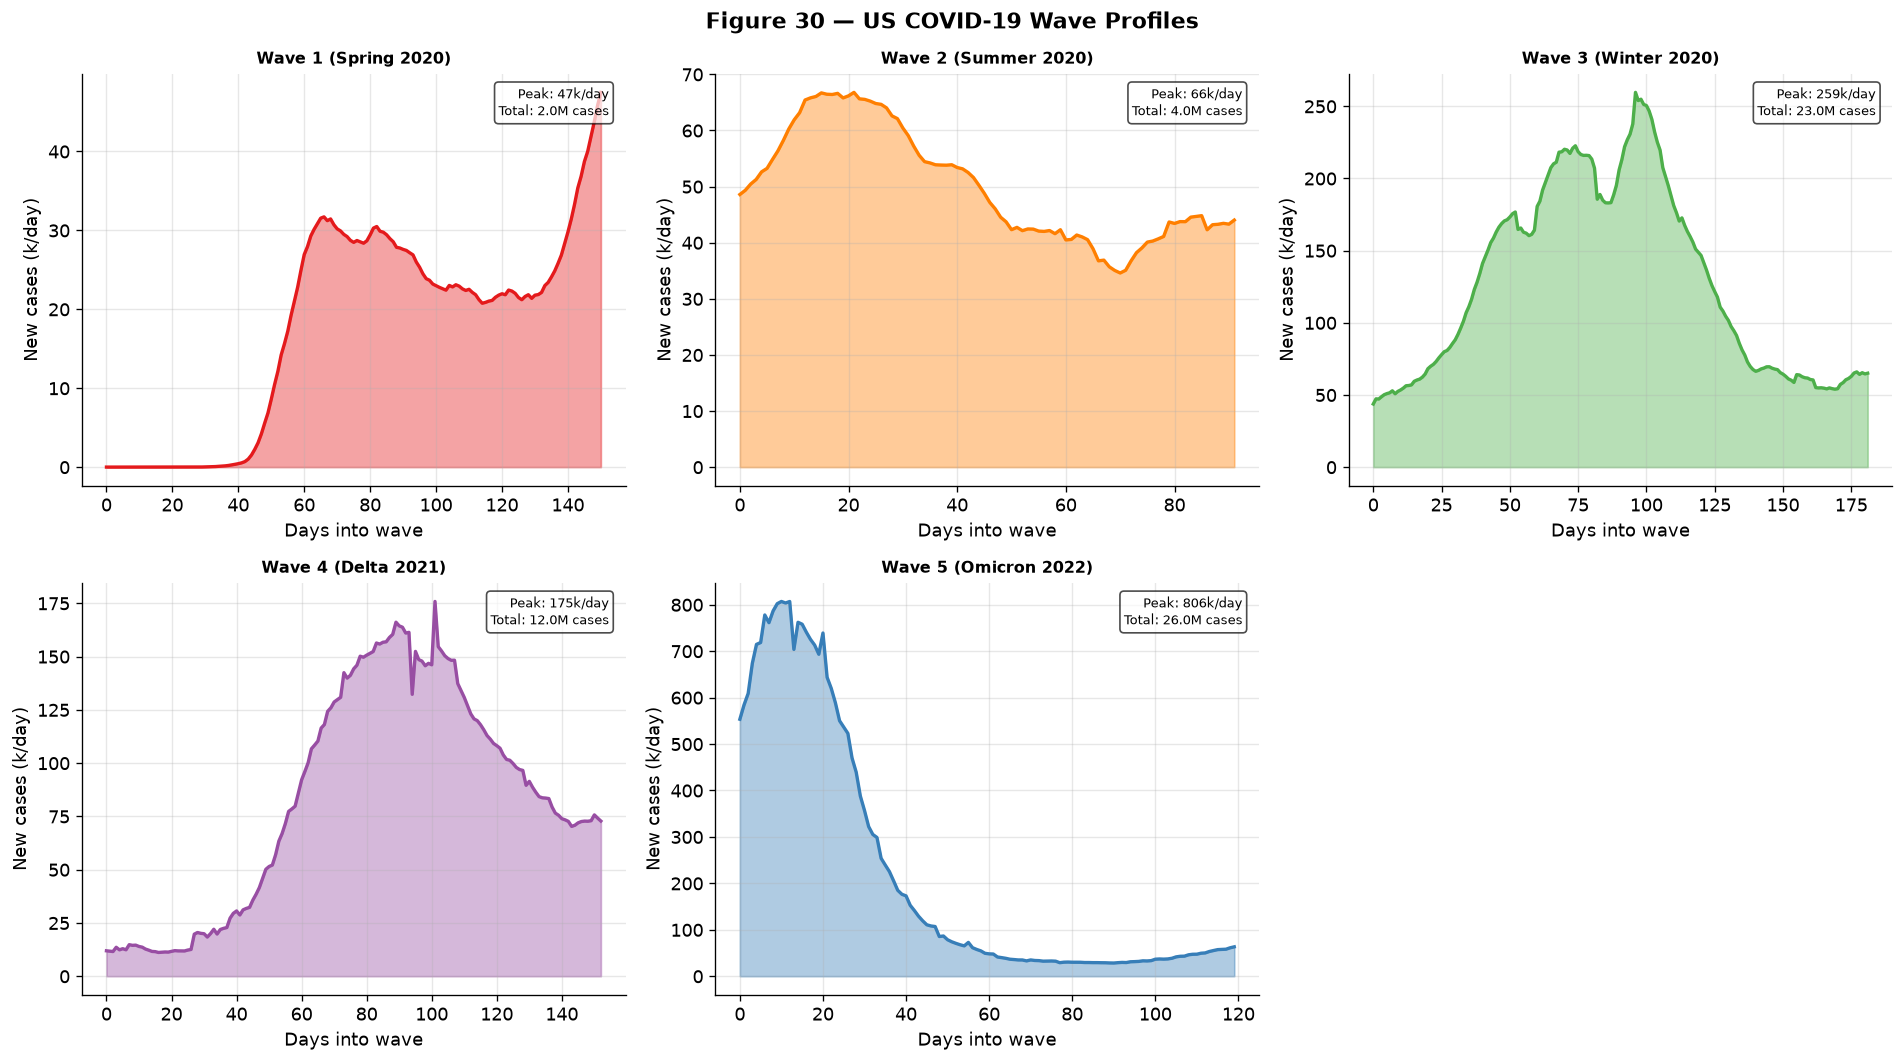

Figure 30 saved.


,Wave,Total cases,Total deaths,CFR (%),Peak cases/day
0,Wave 1 (Spring 2020),"2,653,313","127,462",4.80,"47,482"
1,Wave 2 (Summer 2020),"4,559,439","78,748",1.73,"66,783"
2,Wave 3 (Winter 2020),"23,169,733","343,962",1.48,"259,616"
3,Wave 4 (Delta 2021),"12,633,616","150,902",1.19,"175,822"
4,Wave 5 (Omicron 2022),"26,408,606","167,401",0.63,"806,927"


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('Figure 30 — US COVID-19 Wave Profiles', fontsize=13, fontweight='bold')
axes = axes.flatten()

summary_rows = []
for i, (wname, _) in enumerate(US_WAVES.items()):
    wdf = get_wave(df, wname)
    stats = wave_summary(wdf)
    stats['wave'] = wname
    summary_rows.append(stats)

    ax = axes[i]
    ax.fill_between(range(len(wdf)), wdf.new_cases_smooth/1e3,
                    alpha=0.4, color=WAVE_COLORS[i])
    ax.plot(wdf.new_cases_smooth/1e3, color=WAVE_COLORS[i], lw=2)
    ax.set_title(wname, fontsize=9.5, fontweight='bold')
    ax.set_xlabel('Days into wave')
    ax.set_ylabel('New cases (k/day)')
    ax.annotate(f"Peak: {int(stats['peak_cases_per_day']/1e3)}k/day\n"
                f"Total: {int(stats['total_cases']/1e6):.1f}M cases",
                xy=(0.97, 0.97), xycoords='axes fraction',
                ha='right', va='top', fontsize=8,
                bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.7))

axes[-1].axis('off')  # empty 6th panel

plt.tight_layout()
plt.savefig('../assets/fig30_waves.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 30 saved.")

summary_df = pd.DataFrame(summary_rows)[['wave','total_cases','total_deaths','cfr','peak_cases_per_day']]
summary_df.columns = ['Wave','Total cases','Total deaths','CFR (%)','Peak cases/day']
summary_df['Total cases'] = summary_df['Total cases'].apply(lambda x: f"{int(x):,}")
summary_df['Total deaths'] = summary_df['Total deaths'].apply(lambda x: f"{int(x):,}")
summary_df['CFR (%)'] = summary_df['CFR (%)'].apply(lambda x: f"{x:.2f}")
summary_df['Peak cases/day'] = summary_df['Peak cases/day'].apply(lambda x: f"{int(x):,}")
summary_df

## 7.4 — State-Level Analysis

The state file covers **56 jurisdictions**: 50 states + DC, the 4 territories
(Puerto Rico, Guam, Virgin Islands, Northern Mariana Islands) and American Samoa.

For every jurisdiction we reproduce the same three-panel view as Figure 29 —
**cumulative cases**, **cumulative deaths**, and **daily incidence** (7-day
average) with wave segmentation — arranged as small multiples, **8 states per
figure** (Figures 47–53), ordered by final cumulative case count.

### Handling the left-sparse data (forward-fill)

As established in §7.2, a jurisdiction enters the file on the date of its
*first reported case*; before that date no row exists.  To place all 56
jurisdictions on the same 1158-day timeline we:

1. **reindex** each jurisdiction onto the full date range,
2. **forward-fill** cumulative values within its reported range (no interior
   gaps exist in this file, but the fill protects against data revisions), and
3. **fill 0** for all days before the first reported case.

The daily-new series are the loader's 7-day-smoothed values, consistent with
the national panel.


In [6]:
import matplotlib.dates as mdates

# ── build a uniform 56 × 1158 panel with forward-fill ─────────────────────────
st_all = load_us_states(smooth=True)
full_dates = pd.date_range(st_all.date.min(), st_all.date.max(), freq='D')

def wide(col):
    df = st_all.pivot_table(index='date', columns='state',
                            values=col, aggfunc='last')
    return df.reindex(full_dates).ffill().fillna(0)

cum_cases  = wide('cum_cases')
cum_deaths = wide('cum_deaths')
new_smooth = wide('new_cases_smooth')

def fmt_count(x):
    if x >= 1e6: return f"{x/1e6:.2f}M"
    if x >= 1e3: return f"{x/1e3:.0f}k"
    return f"{x:.0f}"

# ── sanity checks ─────────────────────────────────────────────────────────────
n_days, n_jur = cum_cases.shape
print(f"Panel: {n_jur} jurisdictions × {n_days} days")
print(f"Remaining NaNs after forward-fill: {int(cum_cases.isna().sum().sum())}")
nat_series = df.set_index('date')['cum_cases']
print(f"Sum of jurisdictions == national file (all days): "
      f"{bool(np.allclose(cum_cases.sum(axis=1), nat_series))}")
print("\nTop 5 & bottom 3 jurisdictions by final cumulative cases:")
order_all = cum_cases.iloc[-1].sort_values(ascending=False)
for s in order_all.index[:5].tolist() + ['...'] + order_all.index[-3:].tolist():
    if s == '...':
        print("  ...")
    else:
        print(f"  {s:24s} {fmt_count(order_all[s]):>8s}")

Panel: 56 jurisdictions × 1158 days
Remaining NaNs after forward-fill: 0
Sum of jurisdictions == national file (all days): True

Top 5 & bottom 3 jurisdictions by final cumulative cases:
  California                 12.17M
  Texas                       8.45M
  Florida                     7.54M
  New York                    6.81M
  Illinois                    4.11M
  ...
  Virgin Islands                25k
  Northern Mariana Islands      13k
  American Samoa                 8k


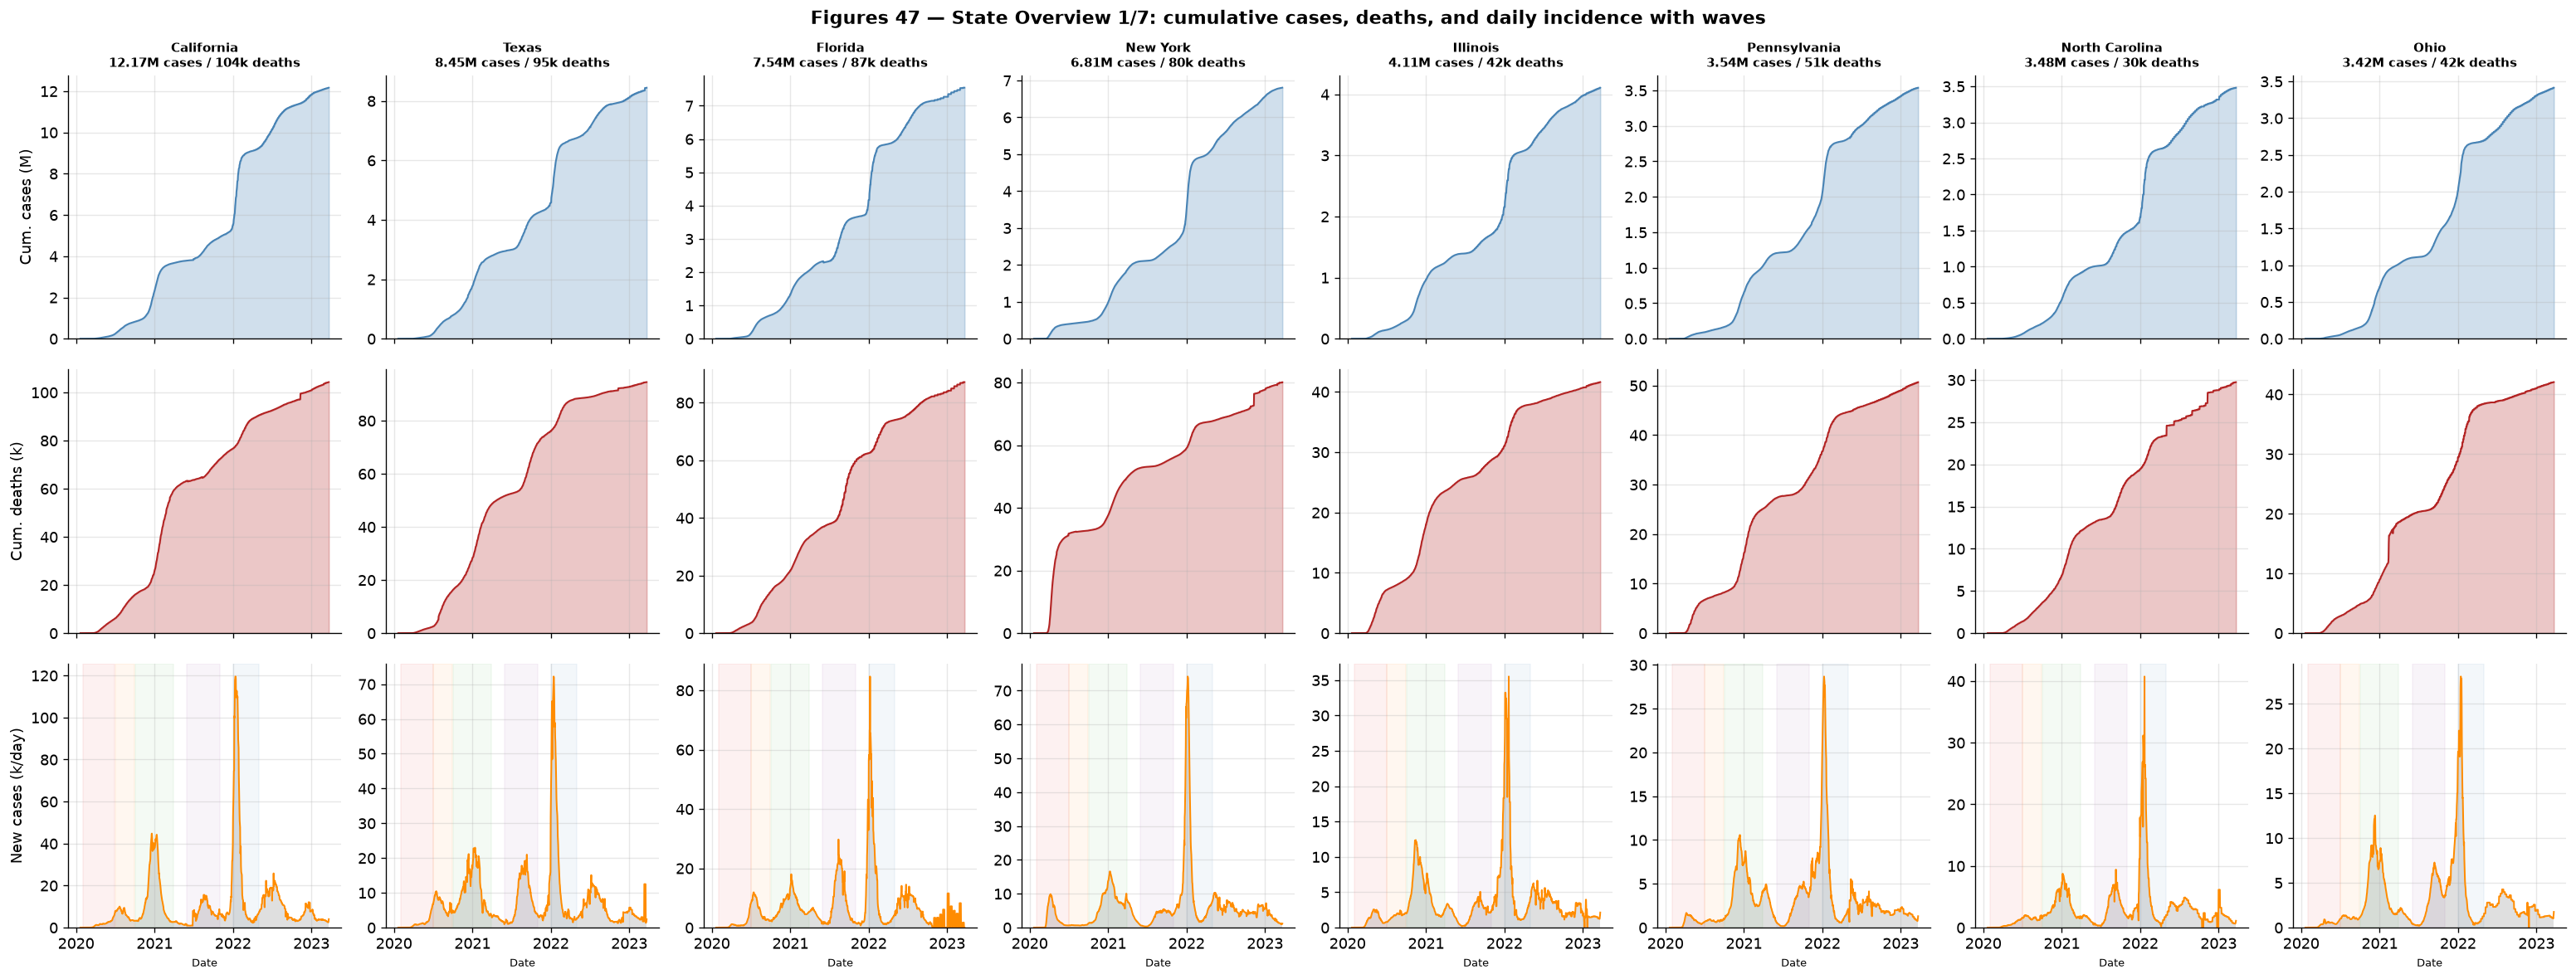

Figure 47 saved.


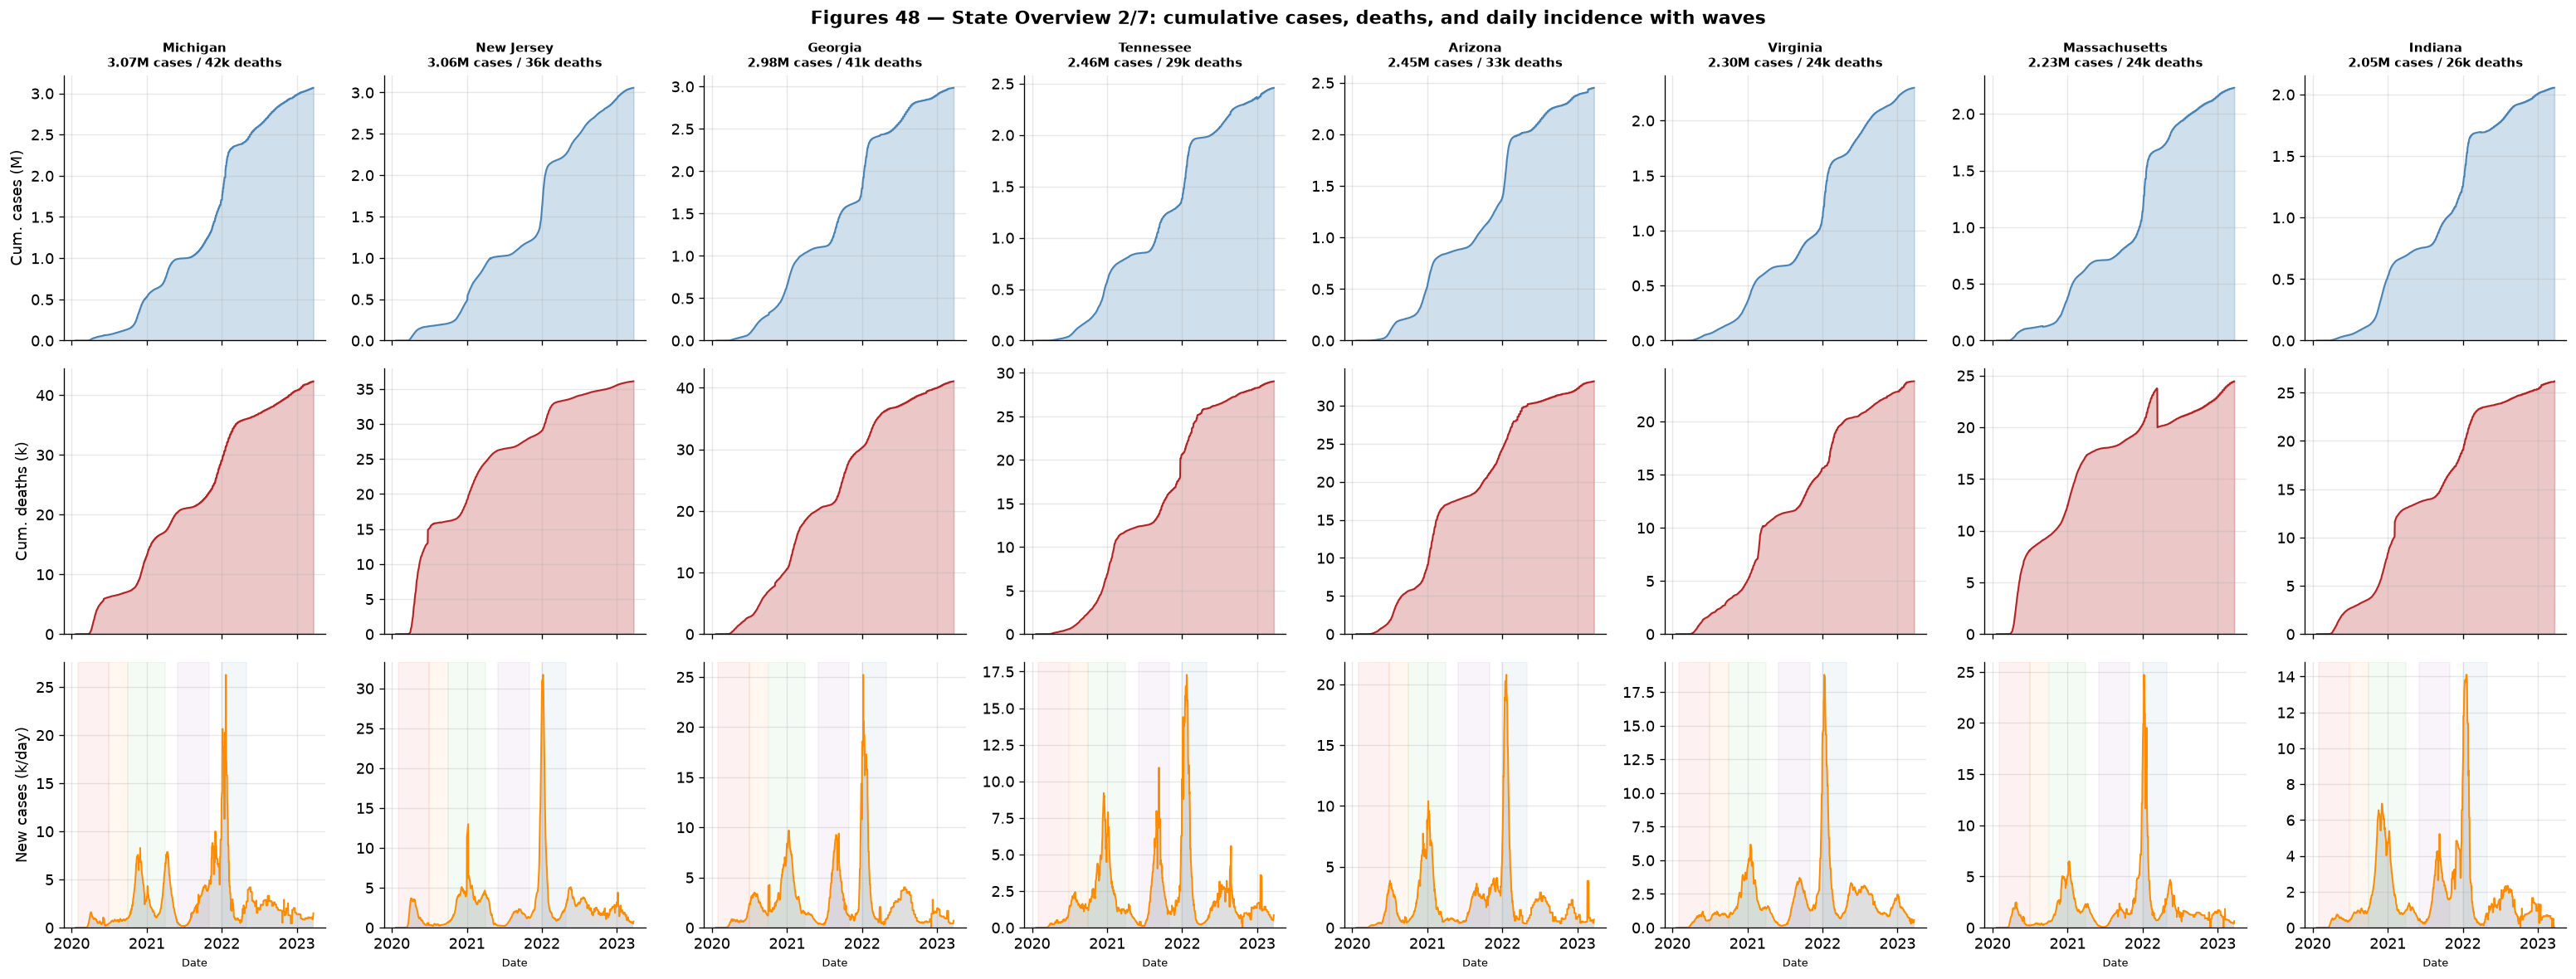

Figure 48 saved.


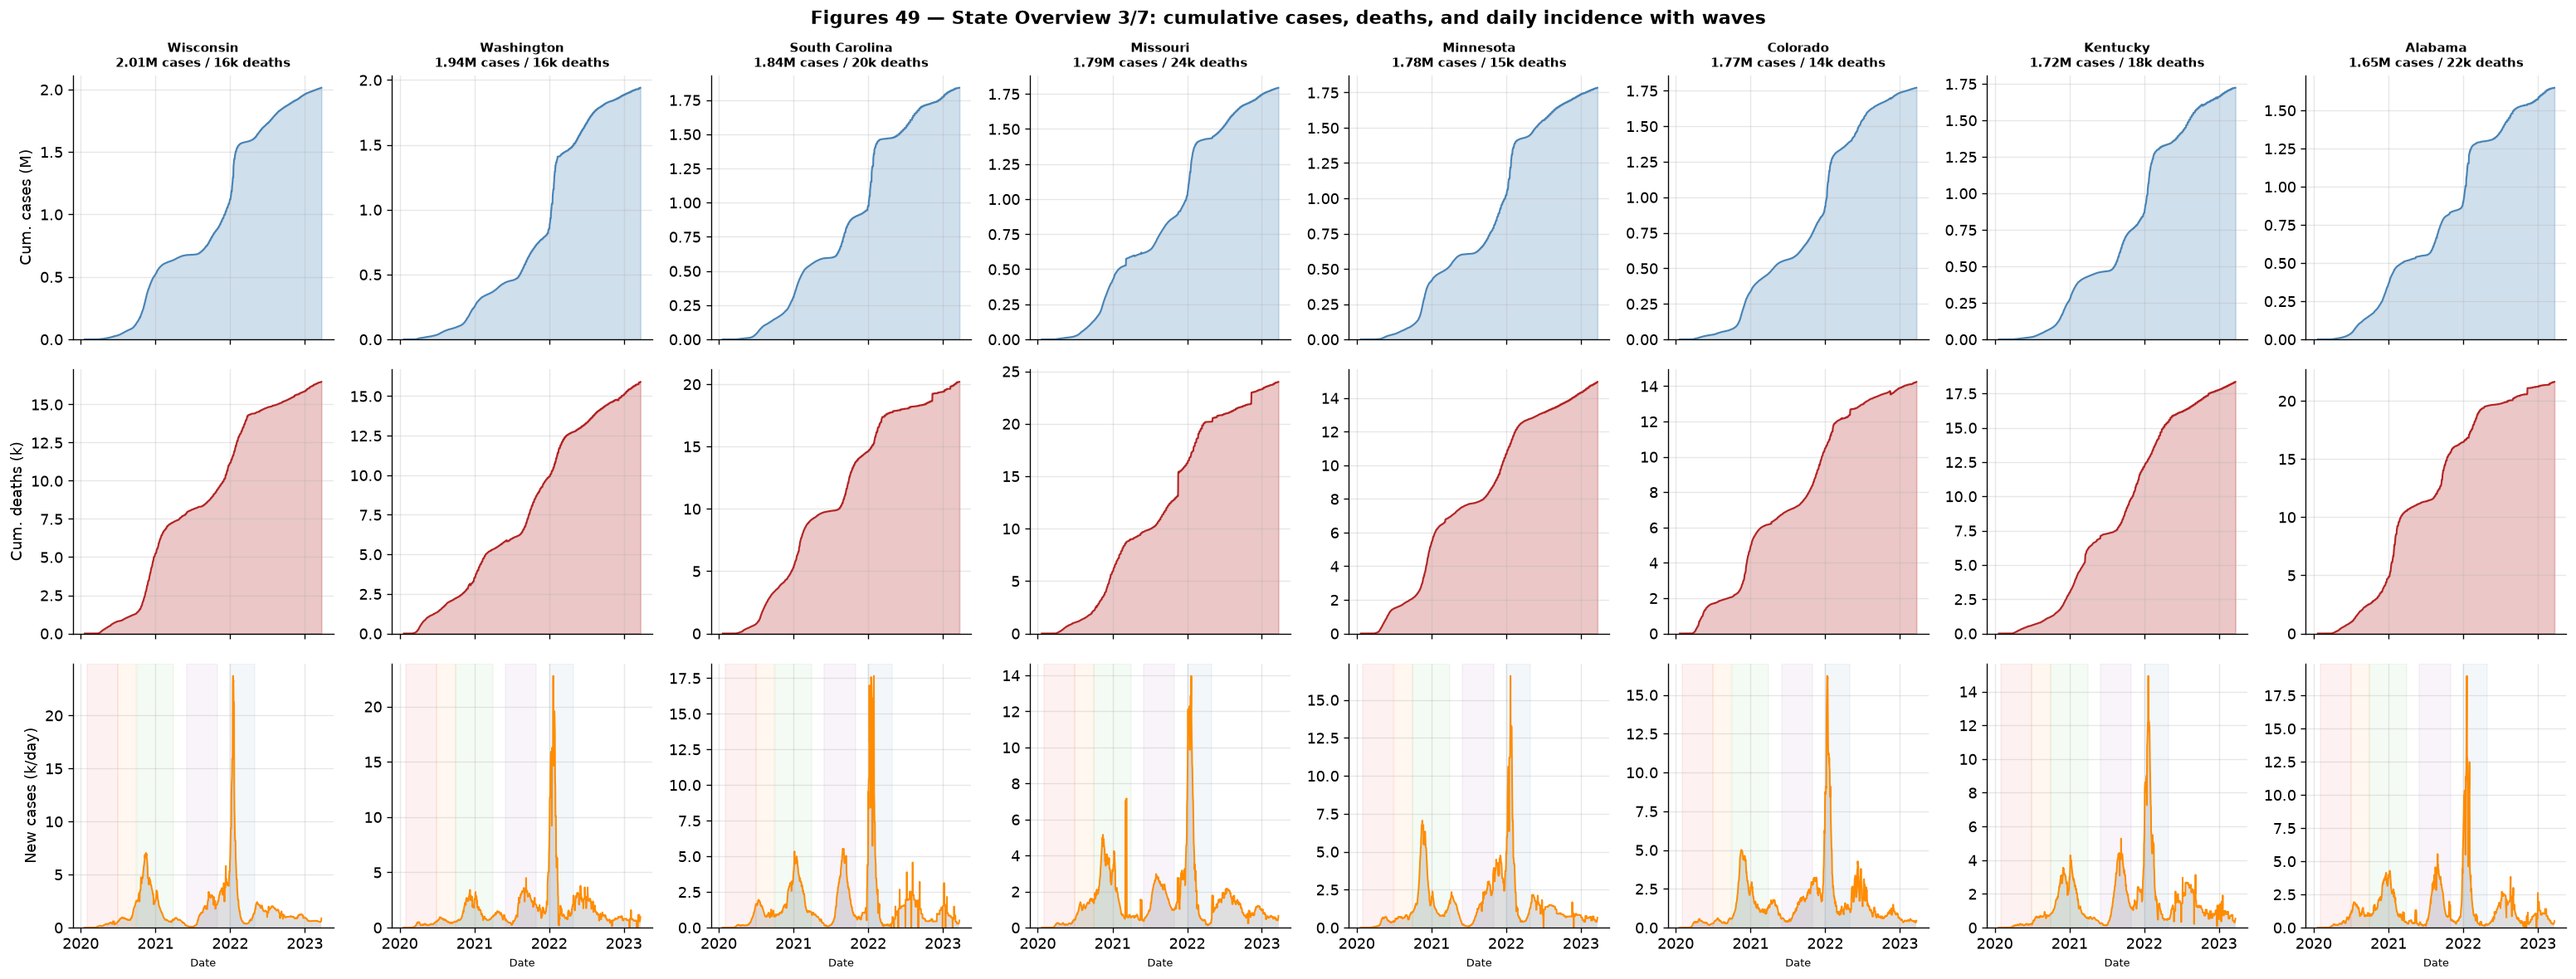

Figure 49 saved.


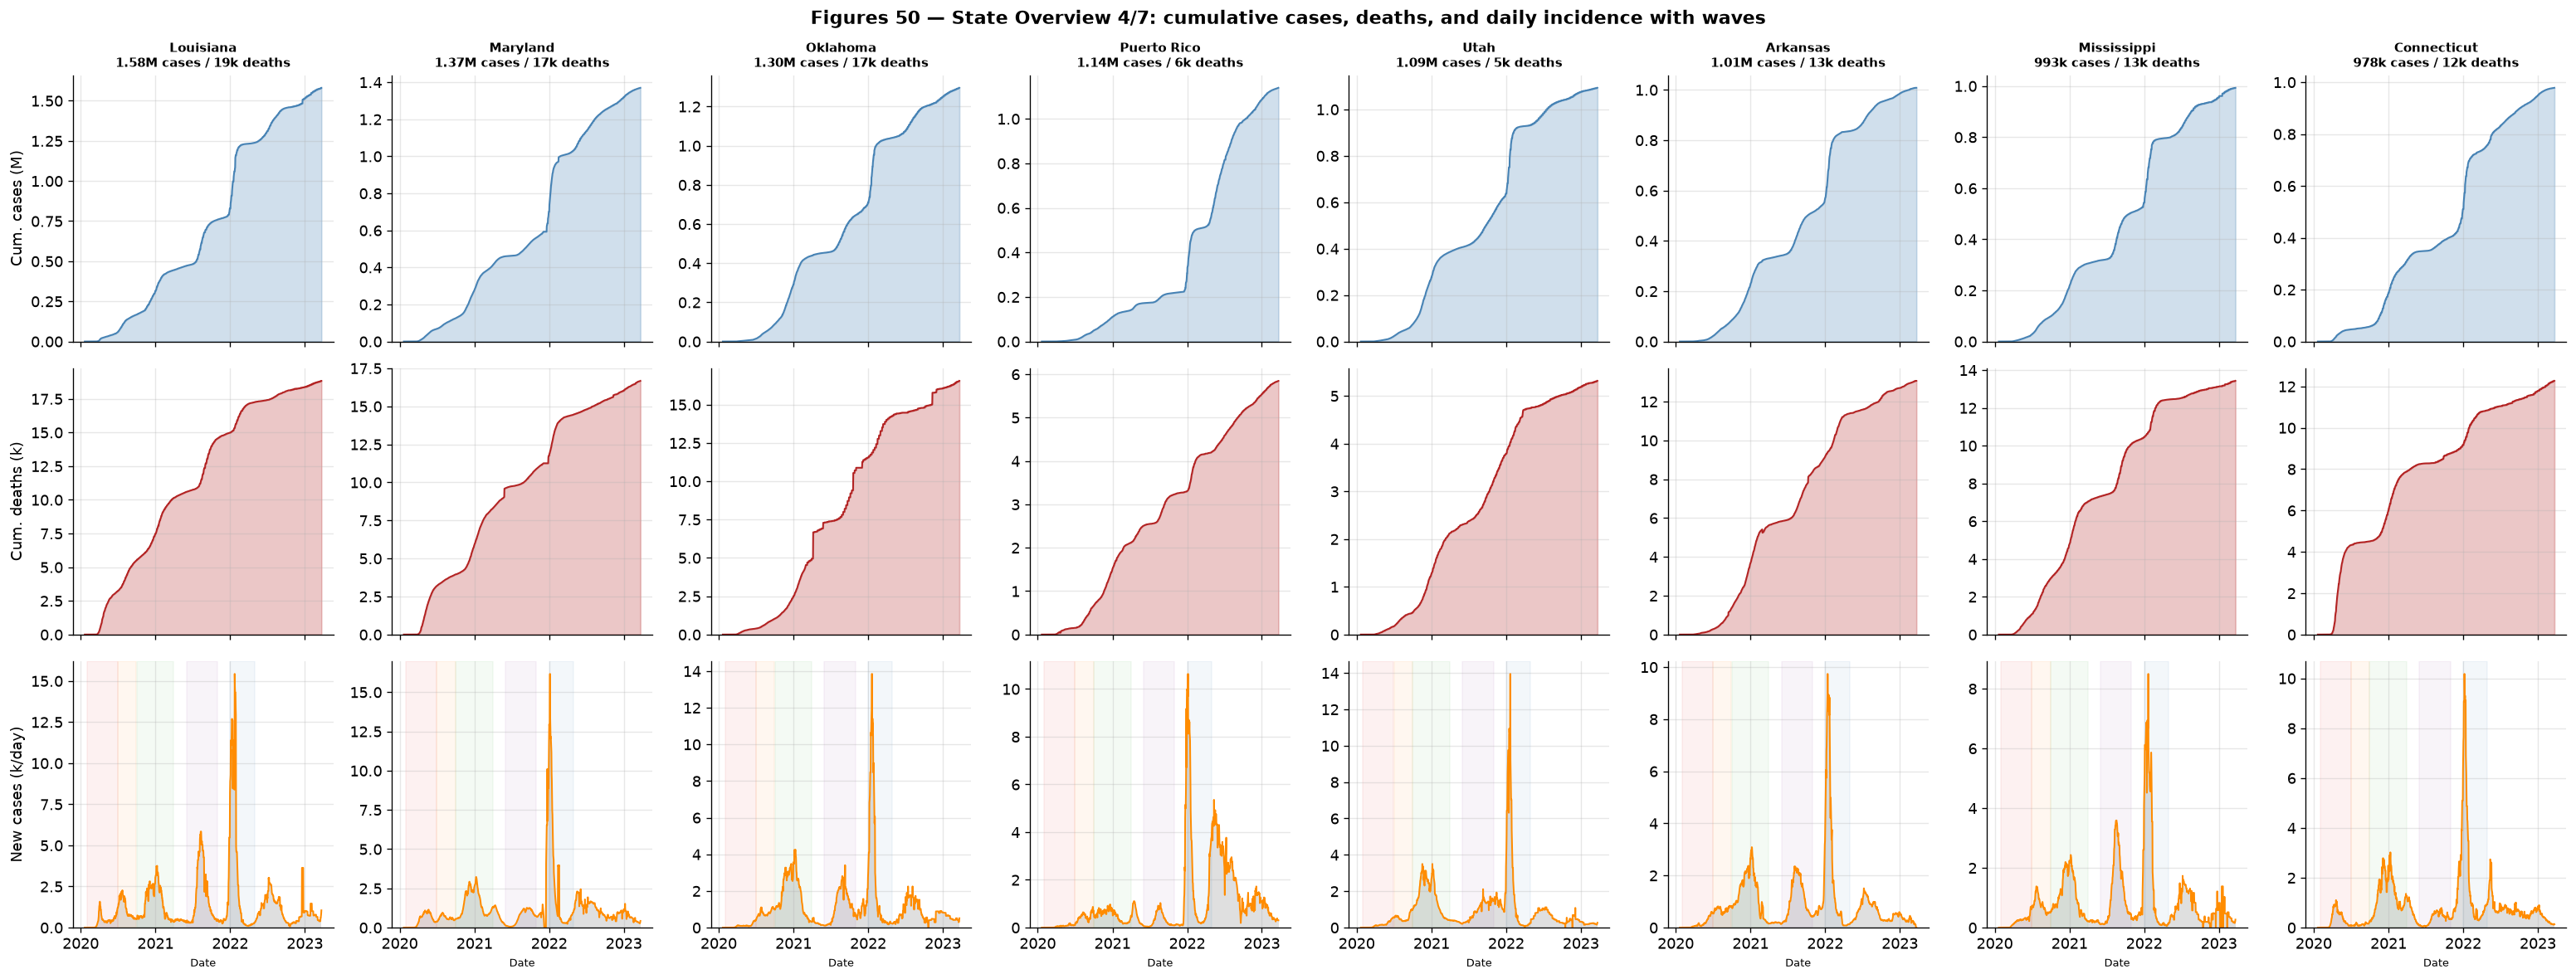

Figure 50 saved.


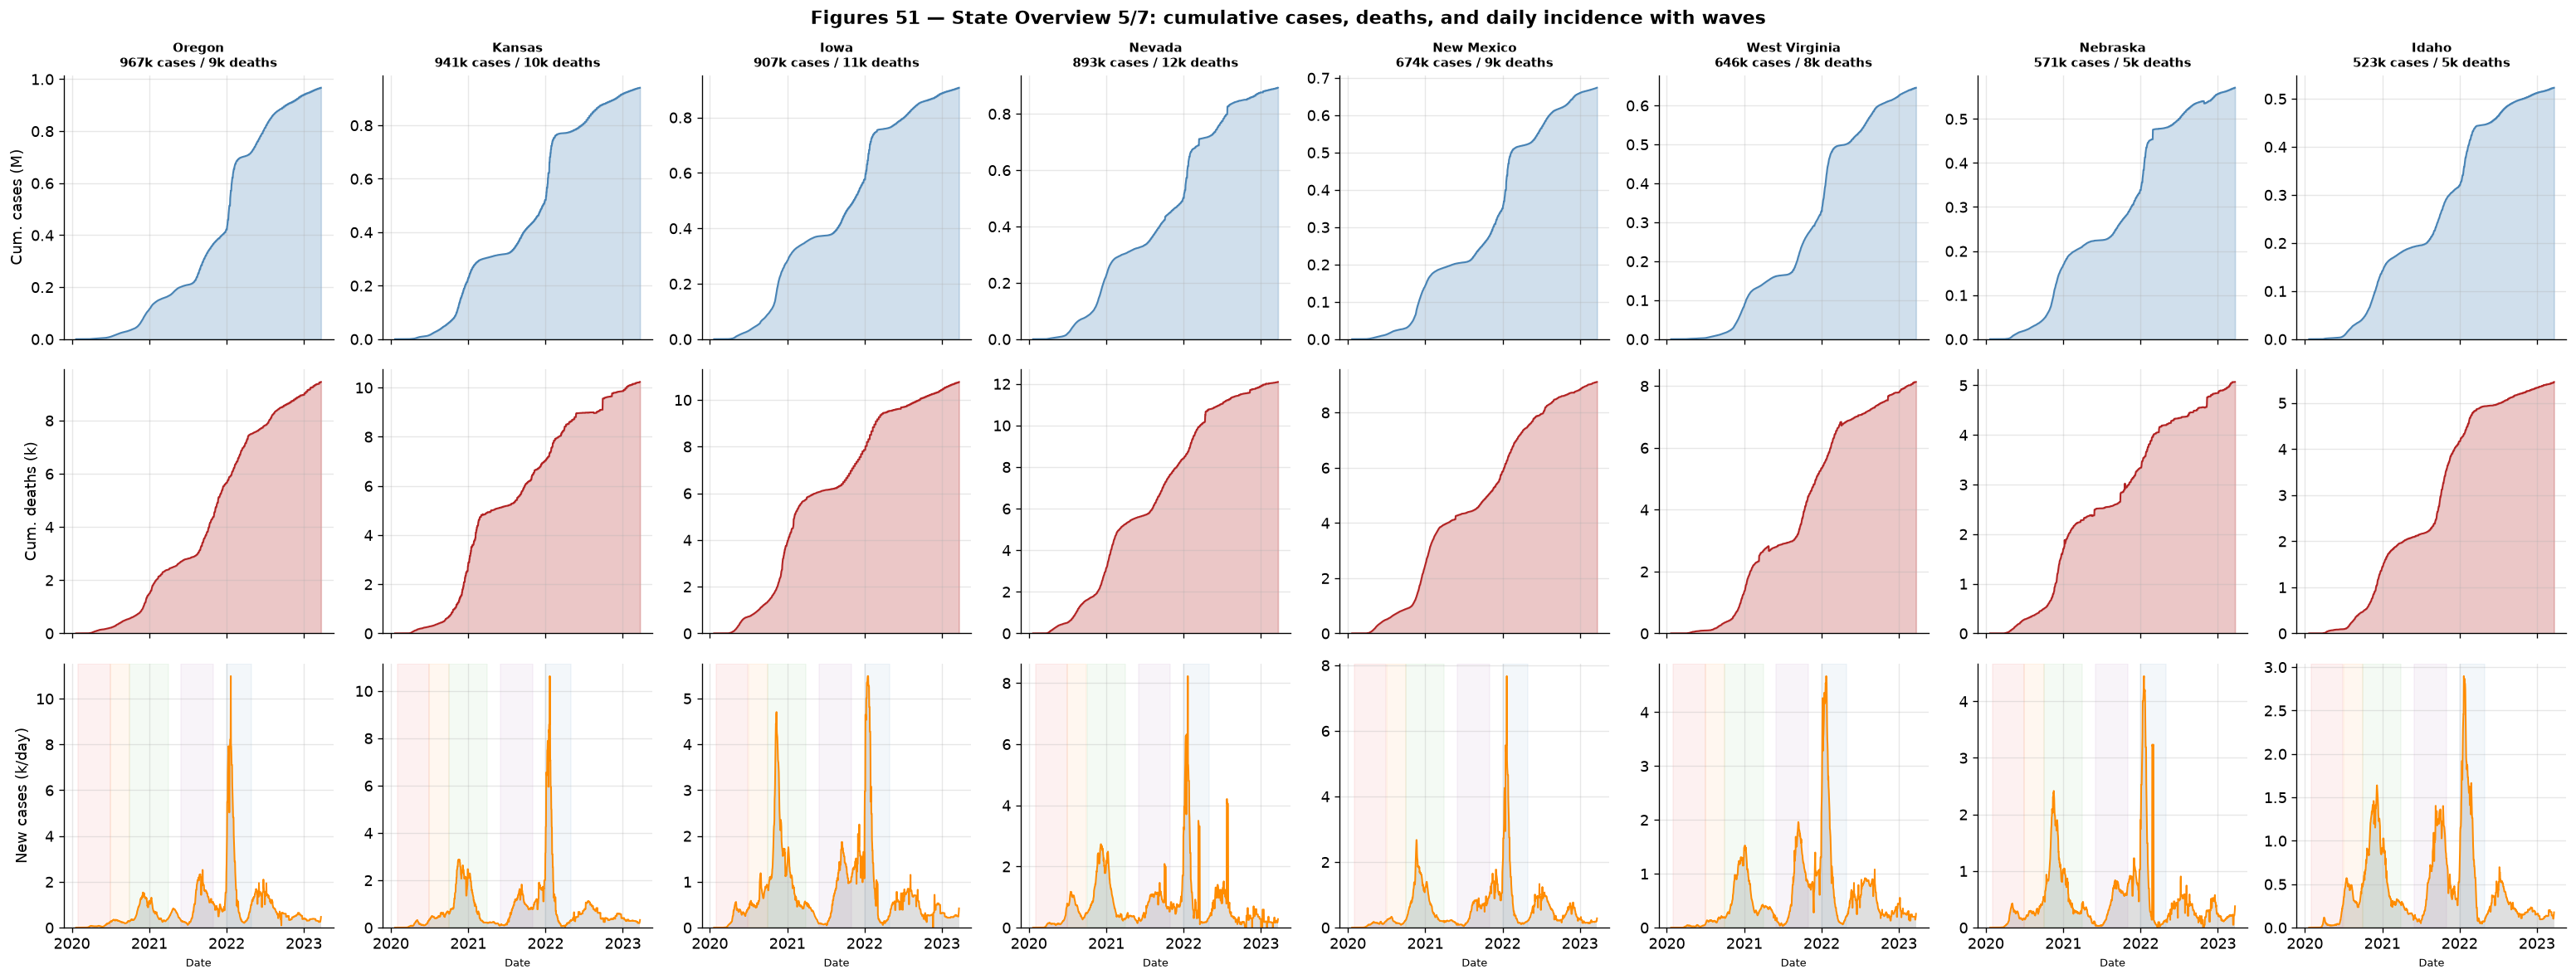

Figure 51 saved.


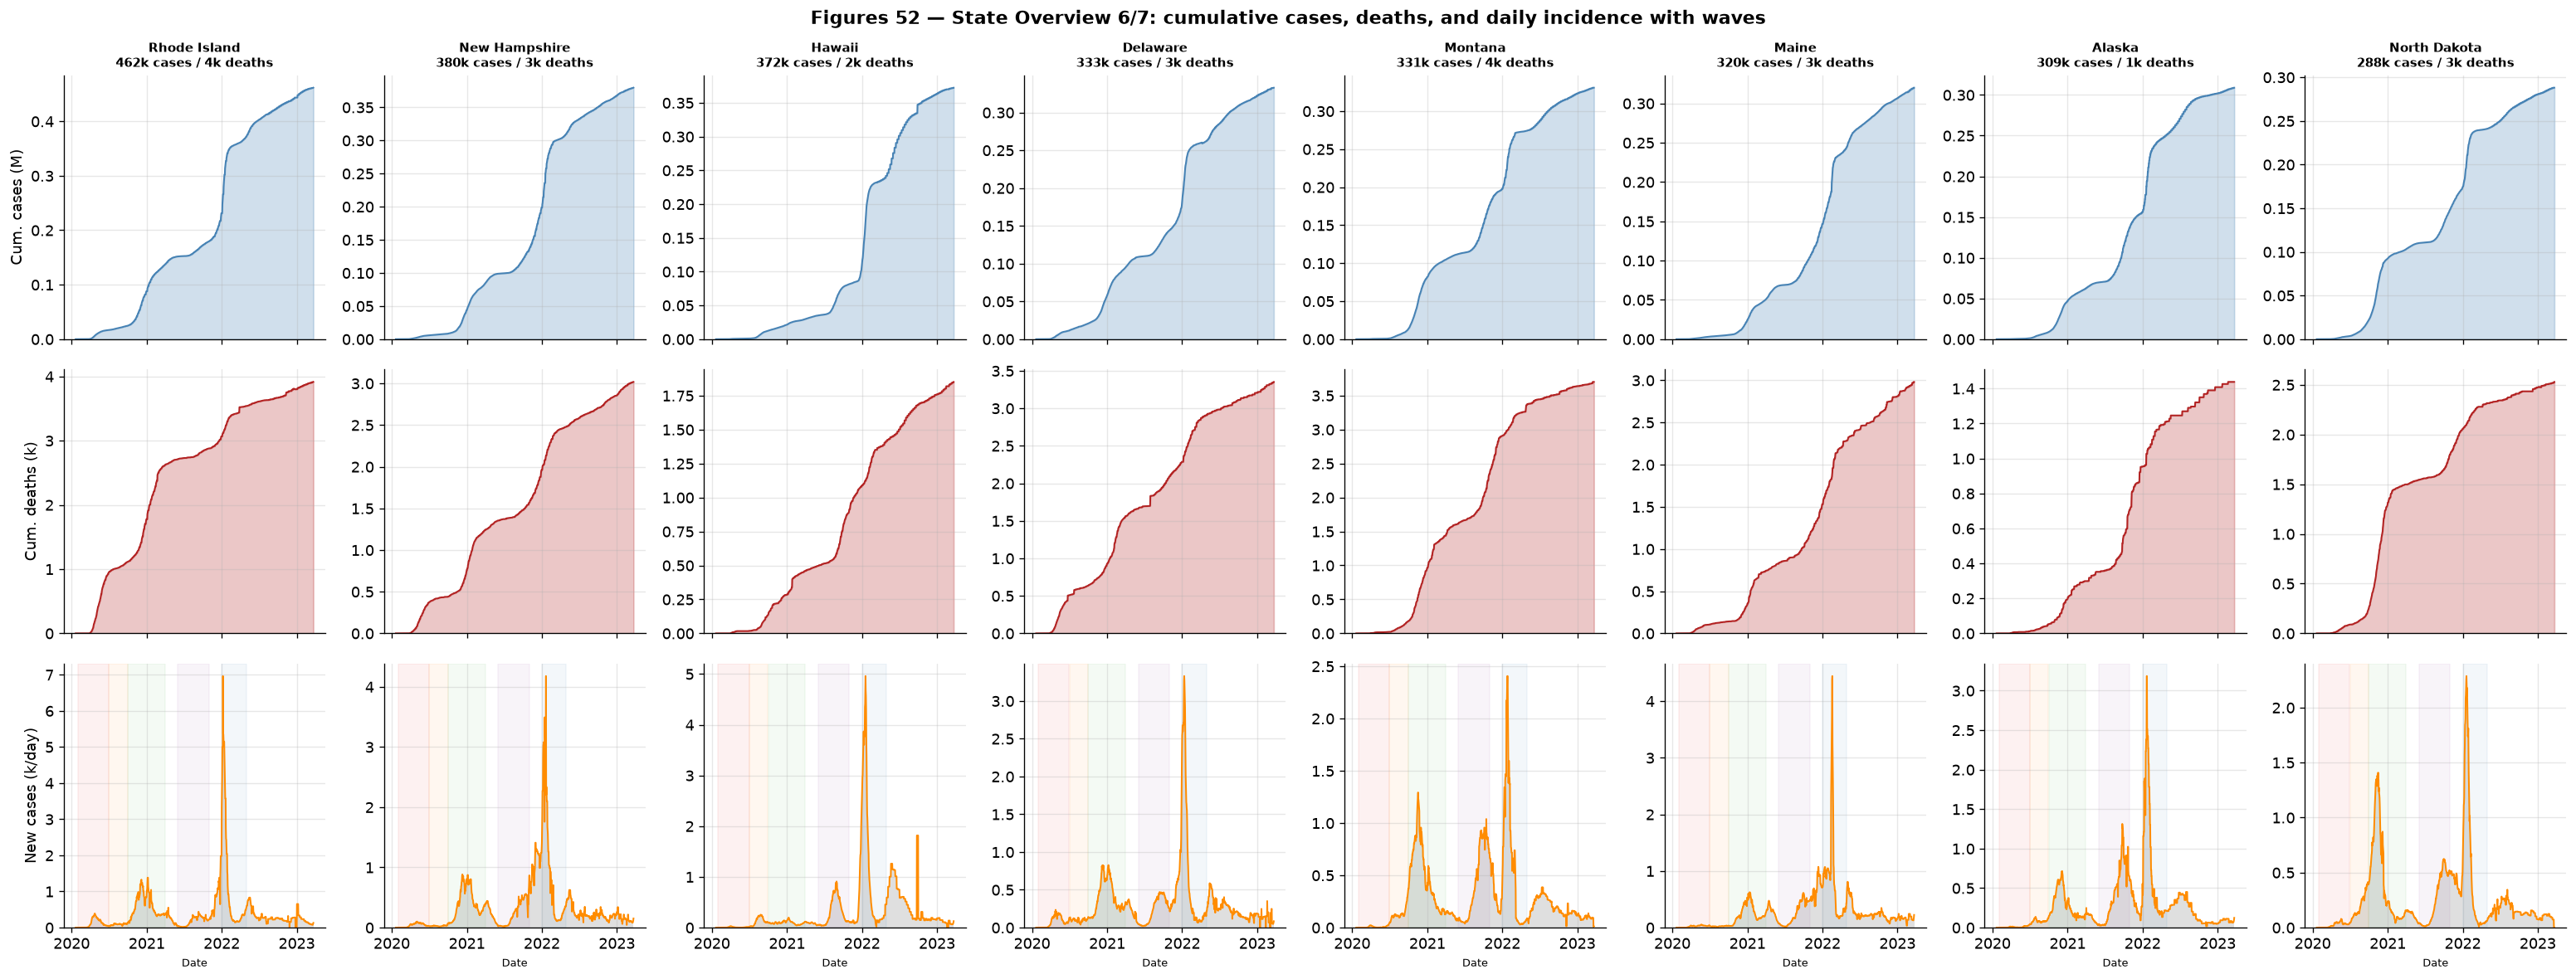

Figure 52 saved.


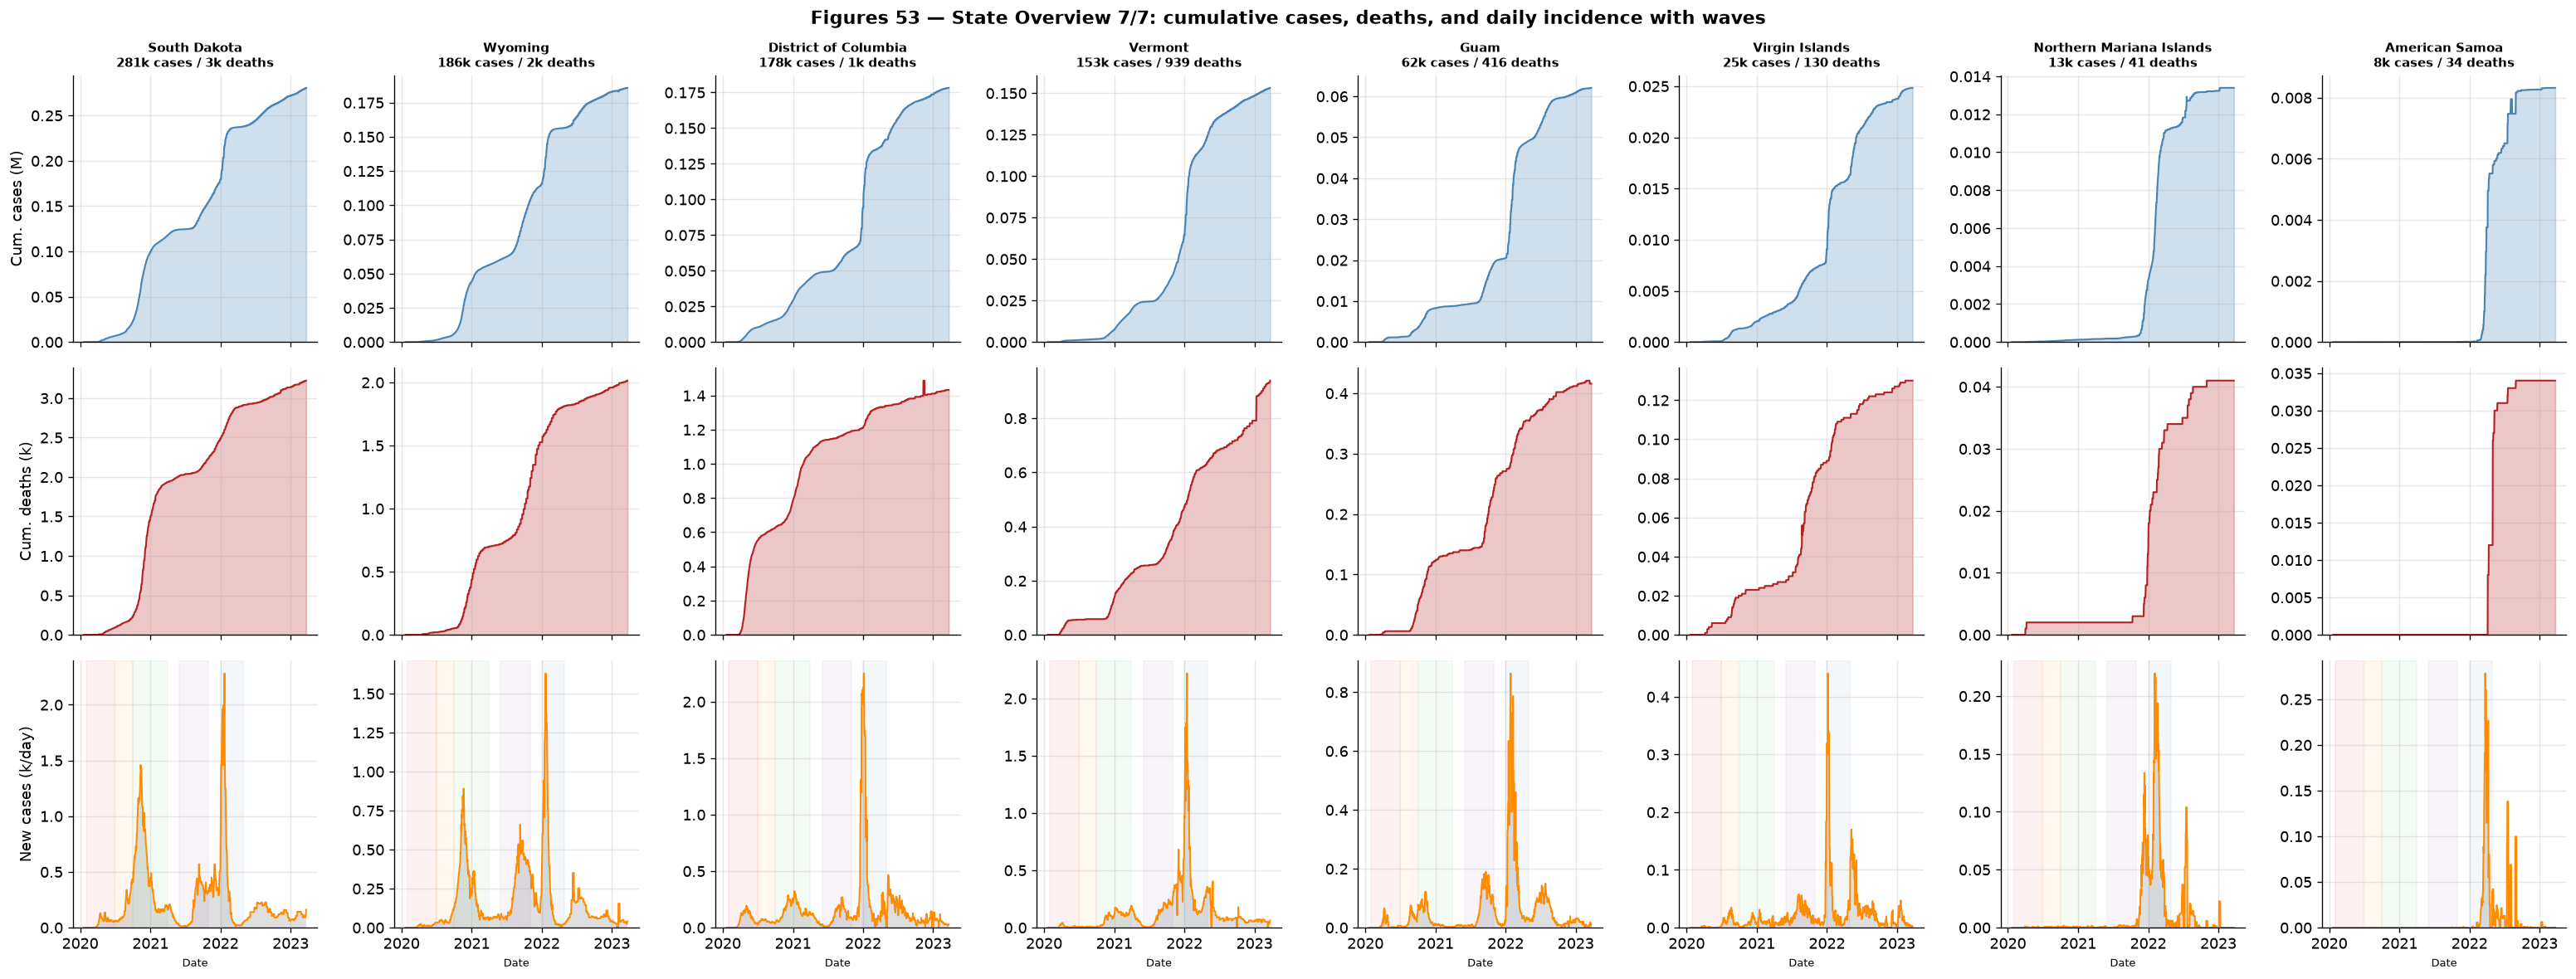

Figure 53 saved.


In [7]:
# ── small multiples: 8 states per figure, same 3-panel layout as national ───
ORDER = cum_cases.iloc[-1].sort_values(ascending=False).index.tolist()
N_PER = 8
n_figs = int(np.ceil(len(ORDER) / N_PER))

for f in range(n_figs):
    chunk = ORDER[f*N_PER:(f+1)*N_PER]
    fig, axes = plt.subplots(3, N_PER, figsize=(26, 10), sharex=True)
    fig.suptitle(f'Figures {47+f} — State Overview {f+1}/{n_figs}: cumulative '
                 f'cases, deaths, and daily incidence with waves',
                 fontsize=13, fontweight='bold')

    for j, s in enumerate(chunk):
        ax_c, ax_d, ax_i = axes[:, j]

        # cumulative cases (M)
        ax_c.fill_between(cum_cases.index, cum_cases[s]/1e6,
                          alpha=0.25, color='steelblue')
        ax_c.plot(cum_cases.index, cum_cases[s]/1e6, color='steelblue', lw=1.2)
        ax_c.set_ylim(bottom=0)

        # cumulative deaths (k)
        ax_d.fill_between(cum_deaths.index, cum_deaths[s]/1e3,
                          alpha=0.25, color='firebrick')
        ax_d.plot(cum_deaths.index, cum_deaths[s]/1e3, color='firebrick', lw=1.2)
        ax_d.set_ylim(bottom=0)

        # daily incidence with wave shading (k/day)
        ax_i.bar(new_smooth.index, new_smooth[s]/1e3, width=1.0,
                 alpha=0.25, color='gray')
        ax_i.plot(new_smooth.index, new_smooth[s]/1e3,
                  color='darkorange', lw=1.2)
        for i, (wname, (ws, we)) in enumerate(US_WAVES.items()):
            ax_i.axvspan(pd.Timestamp(ws), pd.Timestamp(we),
                         alpha=0.06, color=WAVE_COLORS[i])
        ax_i.set_ylim(bottom=0)

        ax_c.set_title(f"{s}\n{fmt_count(cum_cases[s].iloc[-1])} cases / "
                       f"{fmt_count(cum_deaths[s].iloc[-1])} deaths",
                       fontsize=9, fontweight='bold')

        if j == 0:
            ax_c.set_ylabel('Cum. cases (M)')
            ax_d.set_ylabel('Cum. deaths (k)')
            ax_i.set_ylabel('New cases (k/day)')

    for ax in axes[2, :]:
        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        ax.set_xlabel('Date', fontsize=8)

    plt.tight_layout()
    plt.savefig(f'../assets/fig{47+f}_states_{f+1}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Figure {47+f} saved.")

### Per-state summary statistics

Final cumulative cases / deaths, CFR and peak daily incidence for all 56
jurisdictions (ordered by total cases).

In [8]:
peak_dates = new_smooth.idxmax().dt.date
peak_vals  = new_smooth.max()

summary_st = pd.DataFrame({
    'Cumulative cases':    cum_cases.iloc[-1],
    'Cumulative deaths':   cum_deaths.iloc[-1],
    'CFR (%)':             100 * cum_deaths.iloc[-1] / cum_cases.iloc[-1],
    'Peak cases/day':      peak_vals,
    'Peak date':           peak_dates,
}).sort_values('Cumulative cases', ascending=False)

fmt = summary_st.copy()
fmt['Cumulative cases']  = fmt['Cumulative cases'].map(lambda x: f"{int(x):,}")
fmt['Cumulative deaths'] = fmt['Cumulative deaths'].map(lambda x: f"{int(x):,}")
fmt['CFR (%)']           = fmt['CFR (%)'].map(lambda x: f"{x:.2f}")
fmt['Peak cases/day']    = fmt['Peak cases/day'].map(lambda x: f"{int(x):,}")
fmt.index.name = 'State'
fmt

,Cumulative cases,Cumulative deaths,CFR (%),Peak cases/day,Peak date
State,,,,,
California,"12,169,158","104,277",0.86,"119,536",2022-01-12
Texas,"8,447,168","94,518",1.12,"72,195",2022-01-14
Florida,"7,542,869","87,141",1.16,"84,668",2022-01-07
New York,"6,805,271","80,109",1.18,"74,181",2022-01-06
Illinois,"4,107,931","41,618",1.01,"35,516",2022-01-21
Pennsylvania,"3,539,135","50,701",1.43,"28,677",2022-01-09
North Carolina,"3,481,732","29,746",0.85,"40,738",2022-01-21
Ohio,"3,415,254","42,061",1.23,"28,053",2022-01-14
Michigan,"3,068,195","42,311",1.38,"26,268",2022-01-21


## 7.5 — Aviation Mobility Data (T-100 Market + TSA checkpoint)

Two complementary **public** aviation datasets cover the full NYT COVID
period:

| File in `data/` | Source | Granularity | Coverage |
|-----------------|--------|-------------|----------|
| `t100_market_2020_2023.csv.gz` | **BTS T-100 Market**, US carriers, domestic markets (TranStats) | monthly, airport-pair | 2020-01 → 2023-03 (raw, 850k rows) |
| `tsa_checkpoint_daily.csv` | **TSA checkpoint throughput** (tsa.gov, fetched 2026-08-05) | daily | 2019-01-01 → 2023-12-31 (raw) |

From these we build two **national** series (computed in-memory for the
figures, not persisted as CSVs; the state-level tables are derived in §7.6):

- **T-100 monthly scale** — domestic market passengers (US carriers,
  domestic markets) per month, normalised to the Jan-2020 level;
- **TSA daily scale** — daily checkpoint travellers, normalised to the
  Jan-2020 daily mean.

Both series anchor at **Jan 2020 = 1.0**, the last full pre-pandemic month
of US air travel (also the first month of US COVID-19 cases — the NYT
series starts 2020-01-21).

### What the two series measure

Both series are, in absolute terms, **tens of millions of travellers per
month** — so they are shown on a **single absolute axis** in Figure 56
below (per-series normalisation would rescale each to its own baseline and
obscure the actual volumes, so it is *not* used there; the normalised
``scale`` series are only used for the collapse-and-recovery panels 54/55):

- **T-100 Market** counts *domestic* revenue passengers on *US carriers*,
  one row per directional origin→destination market per carrier-month.
  A round trip = two rows (one per direction), and a connecting
  itinerary may appear in several market rows, inflating the passenger
  count relative to boardings.
- **TSA checkpoint** counts *screening crossings*: every traveller who
  proceeds through a US airport security lane, **including international
  departures**.  One traveller on a round trip from the same origin is
  screened twice (once per boarding), and connections add another
  screening only when re-checked.

The two are therefore **not** the same quantity, and neither is "always
the larger".  In Jan-2020 TSA sits above T-100 (64.9 M vs 61.8 M,
international coverage); once international traffic collapses and domestic
itineraries dominate, **T-100 climbs above TSA** throughout the
2020–21 US-dominated recovery; in the final months (2022→2023) the
ordering flips back as international departures return.

### Reading Figure 56 (absolute, not normalised)

Figure 56 draws both monthly totals on the **same absolute axis**
(millions of travellers per month: TSA summed from the daily file, T-100
summed from the market rows).  The gaps you see are real volumes, not
artefacts of a baseline.

- Both series trace the same collapse (≈ 3–4 M in Apr-2020, a few % of the
  ≈ 62–65 M Jan-2020 levels) and the same recovery.  They are close the
  whole way — the gap is at most a few million.
- **Which series is larger flips over time** (TSA ≥ T-100 in 19 of 39
  months): TSA sits above through early 2020 (Jan→Apr, international +
  broad screening coverage) and from 2022-04 to the end (international
  departures returning, so the extra TSA-only volume reappears); T-100
  dominates the domestic-heavy recovery window 2020-05→2021 (border
  closures suppressed the TSA-only international/connecting share,
  while domestic markets — where T-100 counts round-trips and connections
  that TSA does not sum that way — recover faster).
- Data note: TSA revised some early-2020 figures after first publication
  (e.g. the 2020-04-14 trough is now listed as 113,147 on the TSA site vs
  the contemporaneously published 87,534); the daily series linearly
  interpolates the few missing days in the raw file.


In [9]:
# ── national aviation series (in-memory only, not persisted to data/) ────────
# 1) monthly: T-100 Market (US carriers, domestic markets), full NYT period
raw = pd.read_csv('../data/t100_market_2020_2023.csv.gz', low_memory=False)
d = raw[raw.DATA_SOURCE == 'DU']
d = d[d.PASSENGERS > 0]
d['ym'] = d.YEAR * 100 + d.MONTH
d = d[d.ym.between(202001, 202303)]

nat = d.groupby(['YEAR', 'MONTH']).PASSENGERS.sum().reset_index()
nat['date'] = pd.to_datetime(nat.YEAR.astype(str) + '-' + nat.MONTH.astype(str) + '-01')
base_t100 = nat.loc[(nat.YEAR == 2020) & (nat.MONTH == 1), 'PASSENGERS'].iloc[0]
nat['scale'] = nat.PASSENGERS / base_t100
nat.rename(columns={'YEAR': 'year', 'MONTH': 'month'}, inplace=True)

# 2) daily: TSA checkpoint throughput / Jan-2020 mean  (no extrapolation)
tsa = pd.read_csv('../data/tsa_checkpoint_daily.csv', parse_dates=['date'])
base_tsa = tsa[tsa.date.between('2020-01-01', '2020-01-31')].travelers.mean()
dates = pd.date_range('2020-01-21', '2023-03-23', freq='D')
s = tsa.set_index('date').travelers.reindex(dates)
s = s.interpolate().ffill().fillna(base_tsa)

print(f"T-100 raw rows (DU, >0 pax, NYT period): {len(d):,}")
print(f"National Jan-2020 baseline: {base_t100:,.0f} passengers (T-100 market)")
print(f"Monthly table: {len(nat)} months "
      f"({nat.date.min().date()} → {nat.date.max().date()}), no extrapolation")
print(f"Daily series : {len(dates)} days, scale "
      f"{s.min()/base_tsa:.3f} (trough) → {s.iloc[-1]/base_tsa:.3f} (end)")

T-100 raw rows (DU, >0 pax, NYT period): 602,515
National Jan-2020 baseline: 61,848,685 passengers (T-100 market)
Monthly table: 39 months (2020-01-01 → 2023-03-01), no extrapolation
Daily series : 1158 days, scale 0.054 (trough) → 1.170 (end)


In [10]:
# ── assemble the national series in-memory (no derived CSV persisted) ─────────
# The derived national CSVs were removed from data/ (project models use the
# state-level tables of §7.6); these variables only feed the §7.5 figures.
from data_loader import load_tsa_daily

tsa_raw     = load_tsa_daily()
bts_monthly = nat[['year', 'month', 'date', 'scale']].copy()
bts_daily   = pd.DataFrame({'date': dates, 'scale': (s / base_tsa).values})

print("Monthly (T-100) head/tail:")
print(bts_monthly.head(3).to_string(index=False))
print(bts_monthly.tail(2).to_string(index=False))
print(f"Daily: {len(bts_daily)} rows, "
      f"{bts_daily.date.min().date()} → {bts_daily.date.max().date()}")
bts_daily.head()

Monthly (T-100) head/tail:
 year  month       date    scale
 2020      1 2020-01-01 1.000000
 2020      2 2020-02-01 0.971252
 2020      3 2020-03-01 0.558261
 year  month       date    scale
 2023      2 2023-02-01 0.920606
 2023      3 2023-03-01 1.131194
Daily: 1158 rows, 2020-01-21 → 2023-03-23


,date,scale
0,2020-01-21,0.924292
1,2020-01-22,0.891713
2,2020-01-23,1.035673
3,2020-01-24,1.057695
4,2020-01-25,0.814403


In [11]:
# ── T-100 monthly vs TSA monthly — ABSOLUTE volumes (same axis) ──────────────
# No per-series normalisation: both are monthly totals in passengers /
# travellers, so they share one axis.  TSA daily file is summed per month.
tsa_m_abs = tsa_raw.set_index('date')['travelers'].resample('MS').sum()
t100_m_abs = nat.set_index('date')['PASSENGERS']

cmp_abs = pd.DataFrame({'T-100 market': t100_m_abs,
                        'TSA monthly': tsa_m_abs}).dropna()
cmp_abs['gap (M)'] = (cmp_abs['TSA monthly'] - cmp_abs['T-100 market']) / 1e6
print("Absolute monthly volumes (millions):")
print((cmp_abs / 1e6).round(2).to_string())
print(f"\nmax |gap| = {cmp_abs['gap (M)'].abs().max():.2f} M "
      f"(month {cmp_abs['gap (M)'].abs().idxmax():%Y-%m%})")
print(f"TSA >= T-100 in {(cmp_abs['gap (M)']>=0).sum()} of {len(cmp_abs)} months"
      f" (T-100 larger in the domestic 2020-21 recovery)")
print(f"Apr-2020:  T-100 {cmp_abs.loc['2020-04-01','T-100 market']/1e6:.2f} M  vs  "
      f"TSA {cmp_abs.loc['2020-04-01','TSA monthly']/1e6:.2f} M")
print(f"Jan-2020:  T-100 {cmp_abs.loc['2020-01-01','T-100 market']/1e6:.2f} M  vs  "
      f"TSA {cmp_abs.loc['2020-01-01','TSA monthly']/1e6:.2f} M")


Absolute monthly volumes (millions):
            T-100 market  TSA monthly  gap (M)
date                                          
2020-01-01         61.85        64.93      0.0
2020-02-01         60.07        61.94      0.0
2020-03-01         34.53        37.11      0.0
2020-04-01          2.90         4.09      0.0
2020-05-01          9.72         7.84     -0.0
2020-06-01         16.27        15.33     -0.0
2020-07-01         22.99        21.94     -0.0
2020-08-01         24.52        23.02     -0.0
2020-09-01         23.97        22.69     -0.0
2020-10-01         28.18        26.87     -0.0
2020-11-01         26.43        26.22     -0.0
2020-12-01         27.39        27.79      0.0
2021-01-01         24.45        24.92      0.0
2021-02-01         24.59        24.63      0.0
2021-03-01         39.49        38.14     -0.0
2021-04-01         43.97        42.09     -0.0
2021-05-01         52.90        50.30     -0.0
2021-06-01         60.29        57.26     -0.0
2021-07-01         66.9

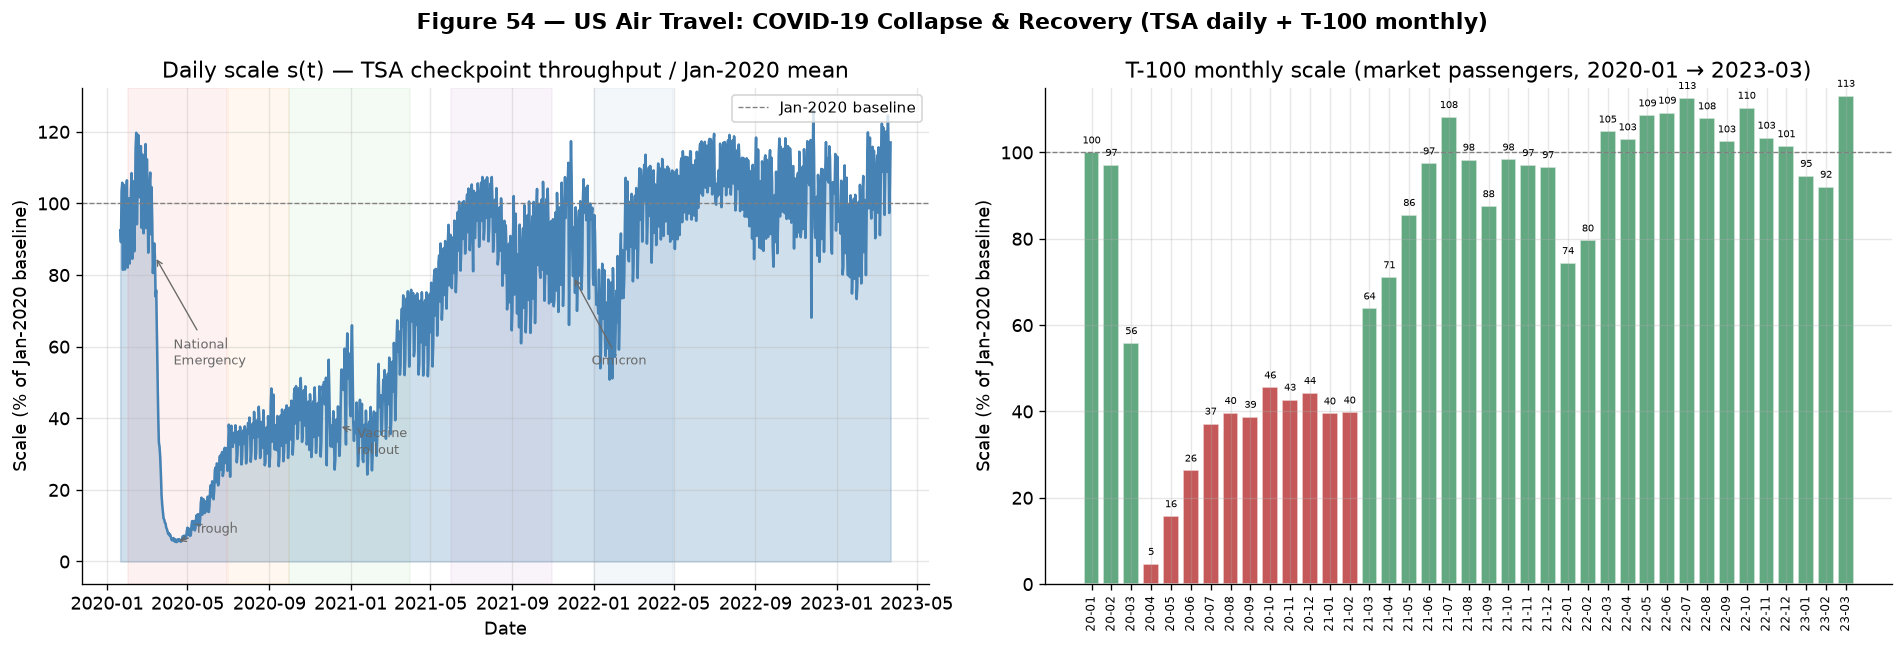

Figure 54 saved.


In [12]:
# ── Figure 54: aviation collapse & recovery ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle('Figure 54 — US Air Travel: COVID-19 Collapse & Recovery '
             '(TSA daily + T-100 monthly)',
             fontsize=13, fontweight='bold')

ax = axes[0]
ax.plot(bts_daily.date, bts_daily.scale*100, color='steelblue', lw=1.5)
ax.fill_between(bts_daily.date, 0, bts_daily.scale*100, alpha=0.25, color='steelblue')
ax.axhline(100, color='gray', lw=0.8, ls='--', label='Jan-2020 baseline')
for i, (wname, (ws, we)) in enumerate(US_WAVES.items()):
    ax.axvspan(pd.Timestamp(ws), pd.Timestamp(we), alpha=0.06, color=WAVE_COLORS[i])
for date_str, label, yp in [('2020-03-13','National\nEmergency',55),
                            ('2020-04-14','Trough',8),
                            ('2020-12-14','Vaccine\nrollout',30),
                            ('2021-12-01','Omicron',55)]:
    xd = pd.Timestamp(date_str)
    v = bts_daily.loc[bts_daily.date == xd, 'scale'].iloc[0] * 100
    ax.annotate(label, xy=(xd, v), xytext=(xd + pd.Timedelta(days=28), yp),
                fontsize=8, color='dimgray',
                arrowprops=dict(arrowstyle='->', color='dimgray', lw=0.8))
ax.set_ylabel('Scale (% of Jan-2020 baseline)')
ax.set_xlabel('Date')
ax.set_title('Daily scale s(t) — TSA checkpoint throughput / Jan-2020 mean')
ax.legend(fontsize=9, loc='upper right')

ax2 = axes[1]
xs = range(len(bts_monthly))
vals = (bts_monthly.scale * 100).values
ax2.bar(xs, vals, color=['firebrick' if v < 50 else 'seagreen' for v in vals],
        alpha=0.75, edgecolor='white')
ax2.axhline(100, color='gray', lw=0.8, ls='--')
ax2.set_xticks(list(xs))
ax2.set_xticklabels(bts_monthly.date.dt.strftime('%y-%m'), rotation=90, fontsize=7)
ax2.set_ylabel('Scale (% of Jan-2020 baseline)')
ax2.set_title('T-100 monthly scale (market passengers, 2020-01 → 2023-03)')
for i, v in enumerate(vals):
    ax2.text(i, v + 1.5, f'{v:.0f}', ha='center', va='bottom', fontsize=6)
ax2.set_ylim(0, 115)

plt.tight_layout()
plt.savefig('../assets/fig54_bts_mobility.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 54 saved.")

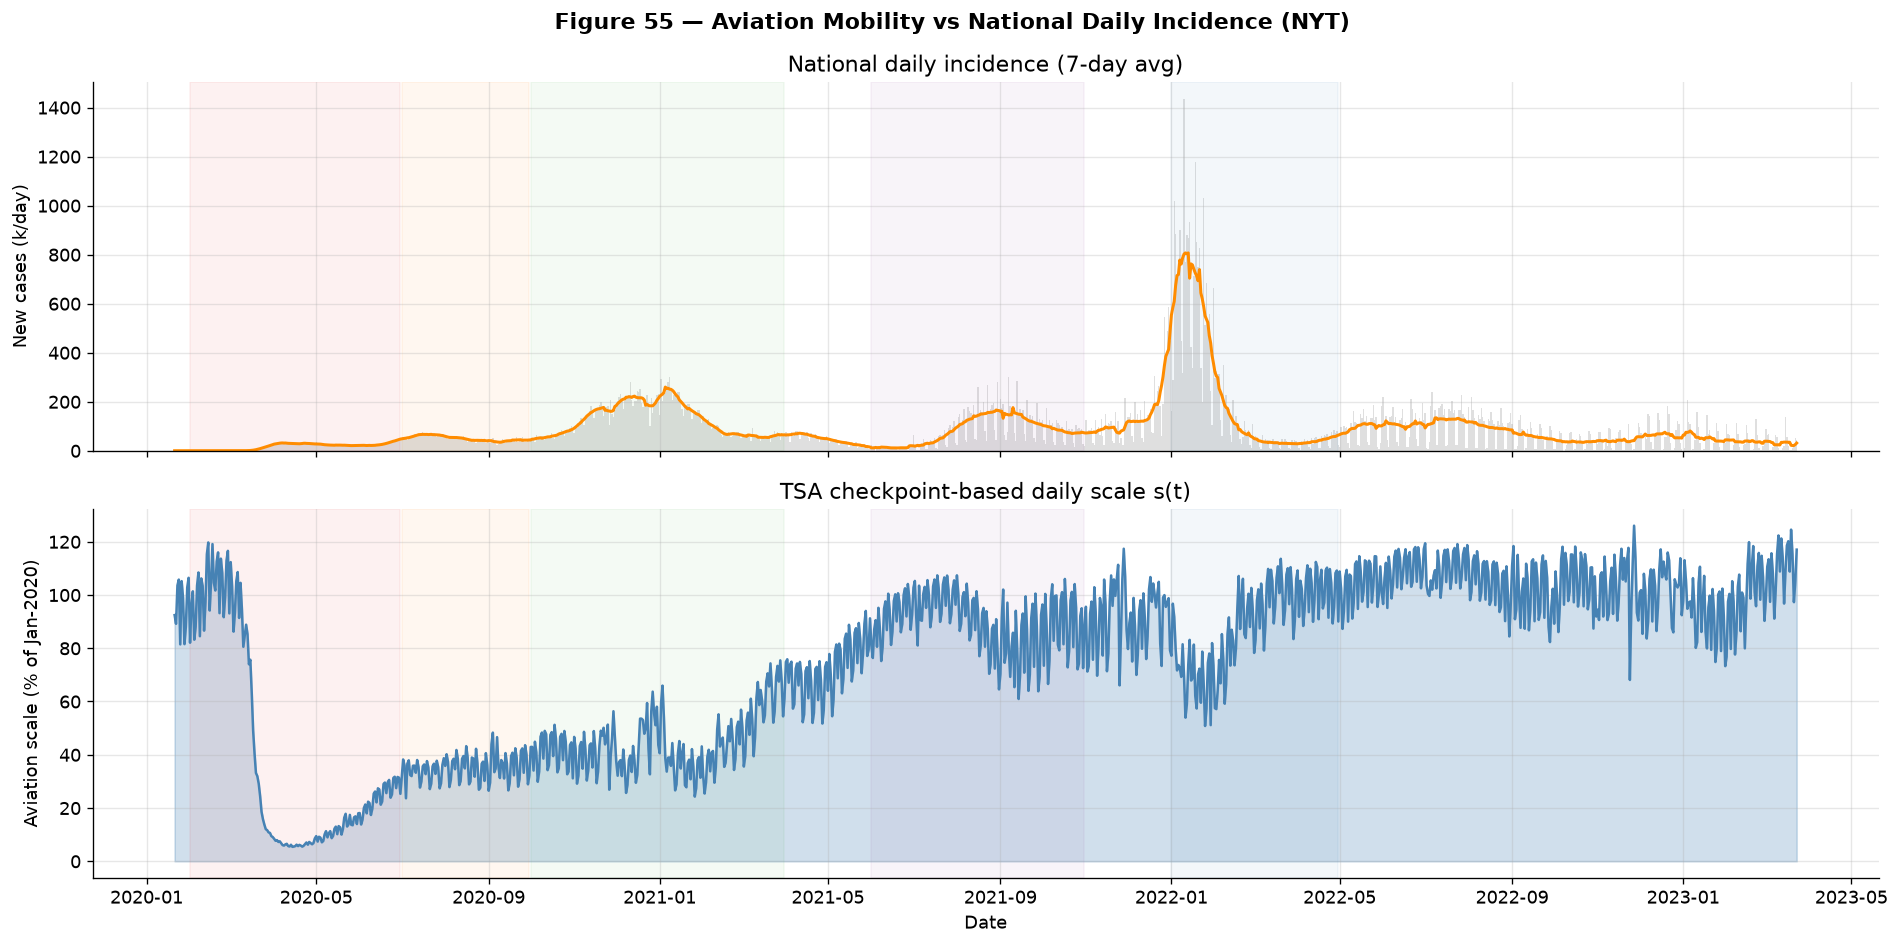

Figure 55 saved.


In [13]:
# ── Figure 55: aviation scale vs national daily incidence (NYT) ───────────────
fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
fig.suptitle('Figure 55 — Aviation Mobility vs National Daily Incidence (NYT)',
             fontsize=13, fontweight='bold')

ax = axes[0]
ax.bar(df.date, df.new_cases/1e3, width=1, alpha=0.25, color='gray')
ax.plot(df.date, df.new_cases_smooth/1e3, color='darkorange', lw=1.8)
ax.set_ylabel('New cases (k/day)')
ax.set_title('National daily incidence (7-day avg)')
for i, (wname, (ws, we)) in enumerate(US_WAVES.items()):
    ax.axvspan(pd.Timestamp(ws), pd.Timestamp(we), alpha=0.06, color=WAVE_COLORS[i])

ax2 = axes[1]
ax2.plot(bts_daily.date, bts_daily.scale*100, color='steelblue', lw=1.5)
ax2.fill_between(bts_daily.date, 0, bts_daily.scale*100, alpha=0.25, color='steelblue')
ax2.set_ylabel('Aviation scale (% of Jan-2020)')
ax2.set_xlabel('Date')
ax2.set_title('TSA checkpoint-based daily scale s(t)')
for i, (wname, (ws, we)) in enumerate(US_WAVES.items()):
    ax2.axvspan(pd.Timestamp(ws), pd.Timestamp(we), alpha=0.06, color=WAVE_COLORS[i])

plt.tight_layout()
plt.savefig('../assets/fig55_bts_vs_cases.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 55 saved.")

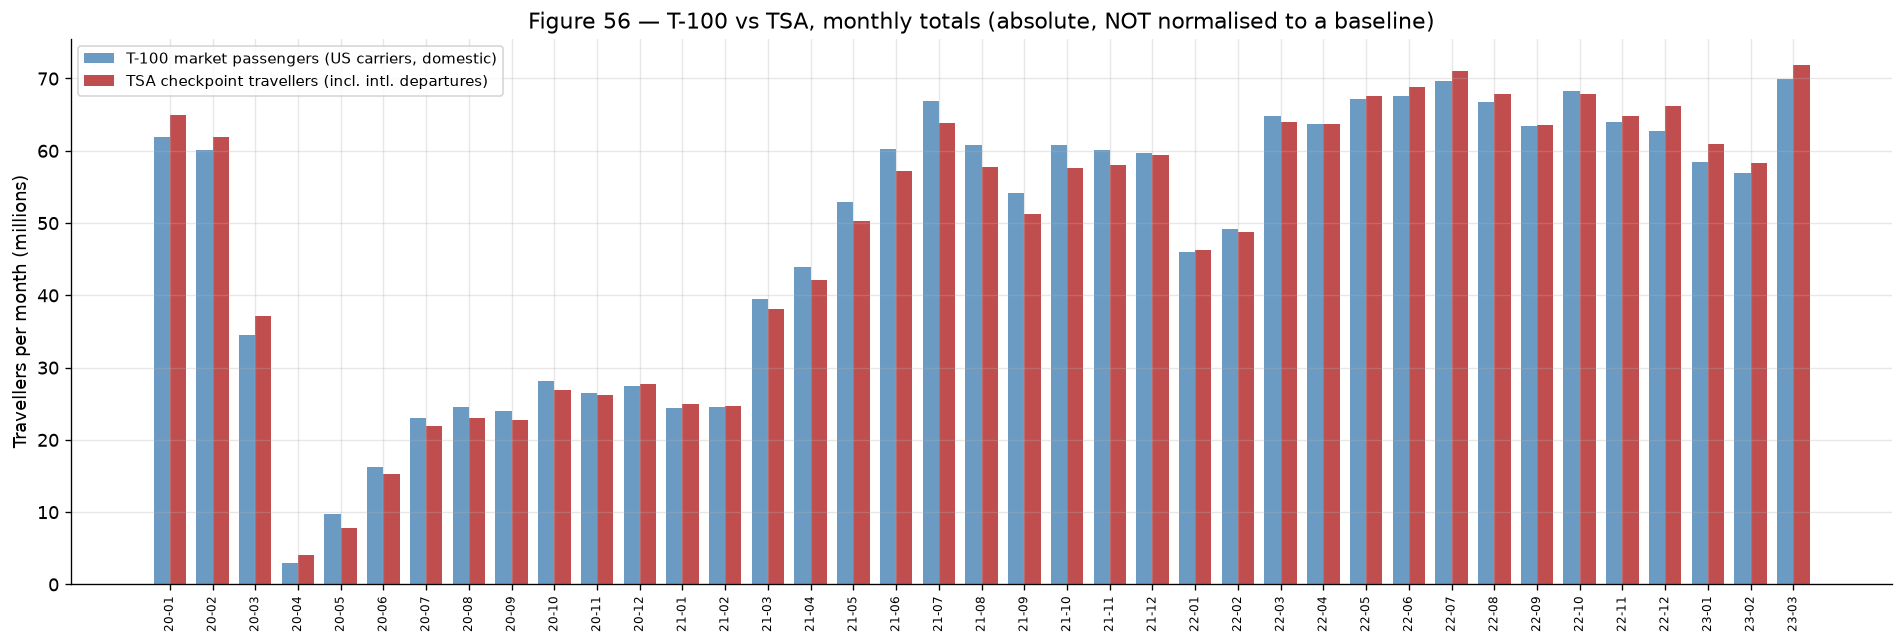

Figure 56 saved.


In [14]:
# ── Figure 56: T-100 vs TSA, ABSOLUTE monthly volumes (not normalised) ───────
fig, ax = plt.subplots(figsize=(16, 5.5))
xs = np.arange(len(cmp_abs))
w = 0.38
ax.bar(xs - w/2, cmp_abs['T-100 market']/1e6, width=w, color='steelblue',
       alpha=0.8, label='T-100 market passengers (US carriers, domestic)')
ax.bar(xs + w/2, cmp_abs['TSA monthly']/1e6, width=w, color='firebrick',
       alpha=0.8, label='TSA checkpoint travellers (incl. intl. departures)')
ax.set_xticks(xs)
ax.set_xticklabels(cmp_abs.index.strftime('%y-%m'), rotation=90, fontsize=7)
ax.set_ylabel('Travellers per month (millions)')
ax.set_title('Figure 56 — T-100 vs TSA, monthly totals (absolute, NOT '
             'normalised to a baseline)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('../assets/fig56_bts_vs_tsa.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 56 saved.")


## 7.6 — State-Level Aviation: State→State Flows & Per-State Traffic

The T-100 Market table carries, for every flight, both airport codes and
their origin / destination states, so it can be aggregated to directional
monthly passengers at **(origin state, dest state)** level — a 56×56
state→state flow table — as well as per-state monthly outbound / inbound
totals.

### Jurisdiction mapping (important T-100 quirks, resolved)

- **DCA → DC**: T-100 codes Washington-National's state as **VA** even though
  the airport is physically in the District of Columbia.  We re-attribute DCA
  to DC (IAD stays VA, BWI stays MD) — otherwise DC would have no data at all.
- **'TT' = Trust Territory**: T-100 uses a single state code for all Pacific
  territories.  We split it by airport: **GU** = GUM+UAM (Guam),
  **MP** = SPN+TIQ+ROP (Northern Mariana Islands), **AS** = PPG (American
  Samoa).  Wake (AWK) and Midway (MDY) carry ~0 passengers and are dropped.
- Result: **all 56 NYT jurisdictions** (50 states + DC + PR + GU + VI + MP +
  AS) have data — none had to be excluded.  AS and MP service is small but
  present; DE's only gap is a genuinely empty Aug-2022 (zero passengers, not
  missing data).

### Files produced

| File | Content |
|------|---------|
| `data/bts_state_pairs_monthly.csv` | origin_state, dest_state, YEAR, MONTH, PASSENGERS (63.7k rows, 56×56) |
| `data/bts_state_monthly.csv` | per state-month: month (YYYY-MM), state, outbound, inbound, net |
| `data/bts_state_jan2020.csv` | per-state Jan-2020 outbound baseline (constant per state) |
| `data/t100_market_2020_2023.csv.gz` | raw T-100 Market extract (852,845 rows) for reproducibility |

`month` is a single time column (e.g. `2020-01`); `net = inbound − outbound`
(a negative value = the state is a net outbound hub for that month).
`bts_state_monthly.csv` omits months with zero traffic (e.g. DE 2022-08);
the per-state Jan-2020 outbound baseline is stored once in
`bts_state_jan2020.csv` (55 states; DE has no Jan-2020 outbound traffic)
instead of being repeated per row.  All files are monthly, T-100's native
granularity.

In [15]:
# ── derive state-level CSVs from the raw T-100 extract ───────────────────────
JURIS = sorted(["AK","AL","AR","AZ","CA","CO","CT","DE","FL","GA","HI","IA","ID",
    "IL","IN","KS","KY","LA","MA","MD","ME","MI","MN","MO","MS","MT","NC","ND",
    "NE","NH","NJ","NM","NV","NY","OH","OK","OR","PA","RI","SC","SD","TN","TX",
    "UT","VA","VT","WA","WI","WV","WY","DC","PR","GU","VI","MP","AS"])
OVERRIDE = {"DCA": "DC",
            "GUM": "GU", "UAM": "GU",
            "SPN": "MP", "TIQ": "MP", "ROP": "MP",
            "PPG": "AS"}
DROP_APTS = {"AWK", "MDY"}

dd = raw[raw.DATA_SOURCE == 'DU'].copy()
dd = dd[dd.PASSENGERS > 0]
dd['ym'] = dd.YEAR * 100 + dd.MONTH
dd = dd[dd.ym.between(202001, 202303)]

ap_state = dd.groupby('ORIGIN')['ORIGIN_STATE_ABR'].agg(
    lambda s: s.value_counts().idxmax()).to_dict()
ap_state.update(OVERRIDE)
for a in DROP_APTS:
    ap_state.pop(a, None)
dd['O'] = dd.ORIGIN.map(ap_state)
dd['D'] = dd.DEST.map(ap_state)
dd = dd.dropna(subset=['O', 'D'])
dd = dd[dd.O.isin(JURIS) & dd.D.isin(JURIS)]

pairs = (dd.groupby(['O', 'D', 'YEAR', 'MONTH']).PASSENGERS.sum()
            .reset_index().rename(columns={'O': 'origin_state', 'D': 'dest_state'}))
pairs.to_csv('../data/bts_state_pairs_monthly.csv', index=False)

out = dd.groupby(['O', 'YEAR', 'MONTH'])['PASSENGERS'].sum().reset_index(name='outbound')
inn = dd.groupby(['D', 'YEAR', 'MONTH'])['PASSENGERS'].sum().reset_index(name='inbound')
st = out.merge(inn, left_on=['O', 'YEAR', 'MONTH'], right_on=['D', 'YEAR', 'MONTH'],
               how='outer')
st['state'] = st.O.fillna(st.D)
st['outbound'] = st.outbound.fillna(0).astype(int)
st['inbound'] = st.inbound.fillna(0).astype(int)
st['net'] = st.inbound - st.outbound
st['month'] = st.YEAR.astype(str) + '-' + st.MONTH.map(lambda m: f'{m:02d}')
st = st.drop(columns=['O', 'D', 'YEAR', 'MONTH'])
st.to_csv('../data/bts_state_monthly.csv', index=False)

jan0 = (st[st.month == '2020-01'][['state', 'outbound']]
            .rename(columns={'outbound': 'outbound_jan2020'})
            .sort_values('state').reset_index(drop=True))
jan0.to_csv('../data/bts_state_jan2020.csv', index=False)

print(f"state→state pairs: {len(pairs)} rows, {pairs.origin_state.nunique()}×"
      f"{pairs.dest_state.nunique()} jurisdictions")
missing = [j for j in JURIS if j not in set(pairs.origin_state) | set(pairs.dest_state)]
print("jurisdictions with NO data:", missing or "none")

state→state pairs: 63721 rows, 56×56 jurisdictions


jurisdictions with NO data: none


In [16]:
# ── per-state coverage & summary ─────────────────────────────────────────────
from data_loader import load_bts_state_pairs, load_bts_state_monthly, load_bts_state_jan2020

st = load_bts_state_monthly()
pr = load_bts_state_pairs()
jan0 = load_bts_state_jan2020()
st = st.merge(jan0, on='state', how='left')
st['ym'] = st.month.str[:4].astype(int) * 100 + st.month.str[5:7].astype(int)
print(f"state-month rows: {len(st)}  (missing months = zero traffic)")
print(f"pairs: {len(pr)} rows")

# scale_out computed here only for the analysis; it is NOT stored in the CSVs
st['scale_out'] = st.outbound / st.outbound_jan2020
summ = (st.assign(ym=st.ym)
          .pivot_table(index='state', columns='ym', values='scale_out')
          .fillna(0))
trough = pd.DataFrame({'trough_scale': summ.min(axis=1),
                       'trough_month': summ.idxmin(axis=1)},
                      index=summ.index)
summ2 = st[st.ym == 202303].set_index('state')[['scale_out']].rename(
    columns={'scale_out': 'end_scale'})
jan = jan0.set_index('state')['outbound_jan2020'].rename('jan2020_outbound')
tab = pd.concat([jan, trough, summ2], axis=1).sort_values('jan2020_outbound', ascending=False)
print("\nPer-state summary (top 12 by Jan-2020 traffic, rest …):")
print(tab.head(12).round(3).to_string())
print("\nStates with the deepest trough:")
print(tab.sort_values('trough_scale').head(10)[['trough_scale','trough_month']].round(3).to_string())
print("\nStates least recovered by 2023-03:")
print(tab.sort_values('end_scale').head(10)[['end_scale']].round(3).to_string())
print("\nTop 10 state→state flows (total, 2020-01..2023-03):")
top = pr.groupby(['origin_state','dest_state']).PASSENGERS.sum().reset_index()
top = top.sort_values('PASSENGERS', ascending=False).head(10)
top['pax_m'] = (top.PASSENGERS/1e6).round(1)
print(top[['origin_state','dest_state','pax_m']].to_string(index=False))

state-month rows: 2171  (missing months = zero traffic)
pairs: 63721 rows

Per-state summary (top 12 by Jan-2020 traffic, rest …):
       jan2020_outbound  trough_scale  trough_month  end_scale
state                                                         
CA            7336075.0         0.042      202004.0      1.018
FL            6945979.0         0.042      202004.0      1.197
TX            6138185.0         0.061      202004.0      1.170
GA            3657366.0         0.050      202004.0      1.071
IL            3047543.0         0.051      202004.0      1.123
NY            2695482.0         0.022      202004.0      1.221
CO            2634257.0         0.049      202004.0      1.237
NC            2572105.0         0.064      202004.0      1.075
NV            2036089.0         0.033      202004.0      1.191
AZ            2002298.0         0.071      202004.0      1.223
WA            1848976.0         0.060      202004.0      1.048
PA            1453428.0         0.047      202004.

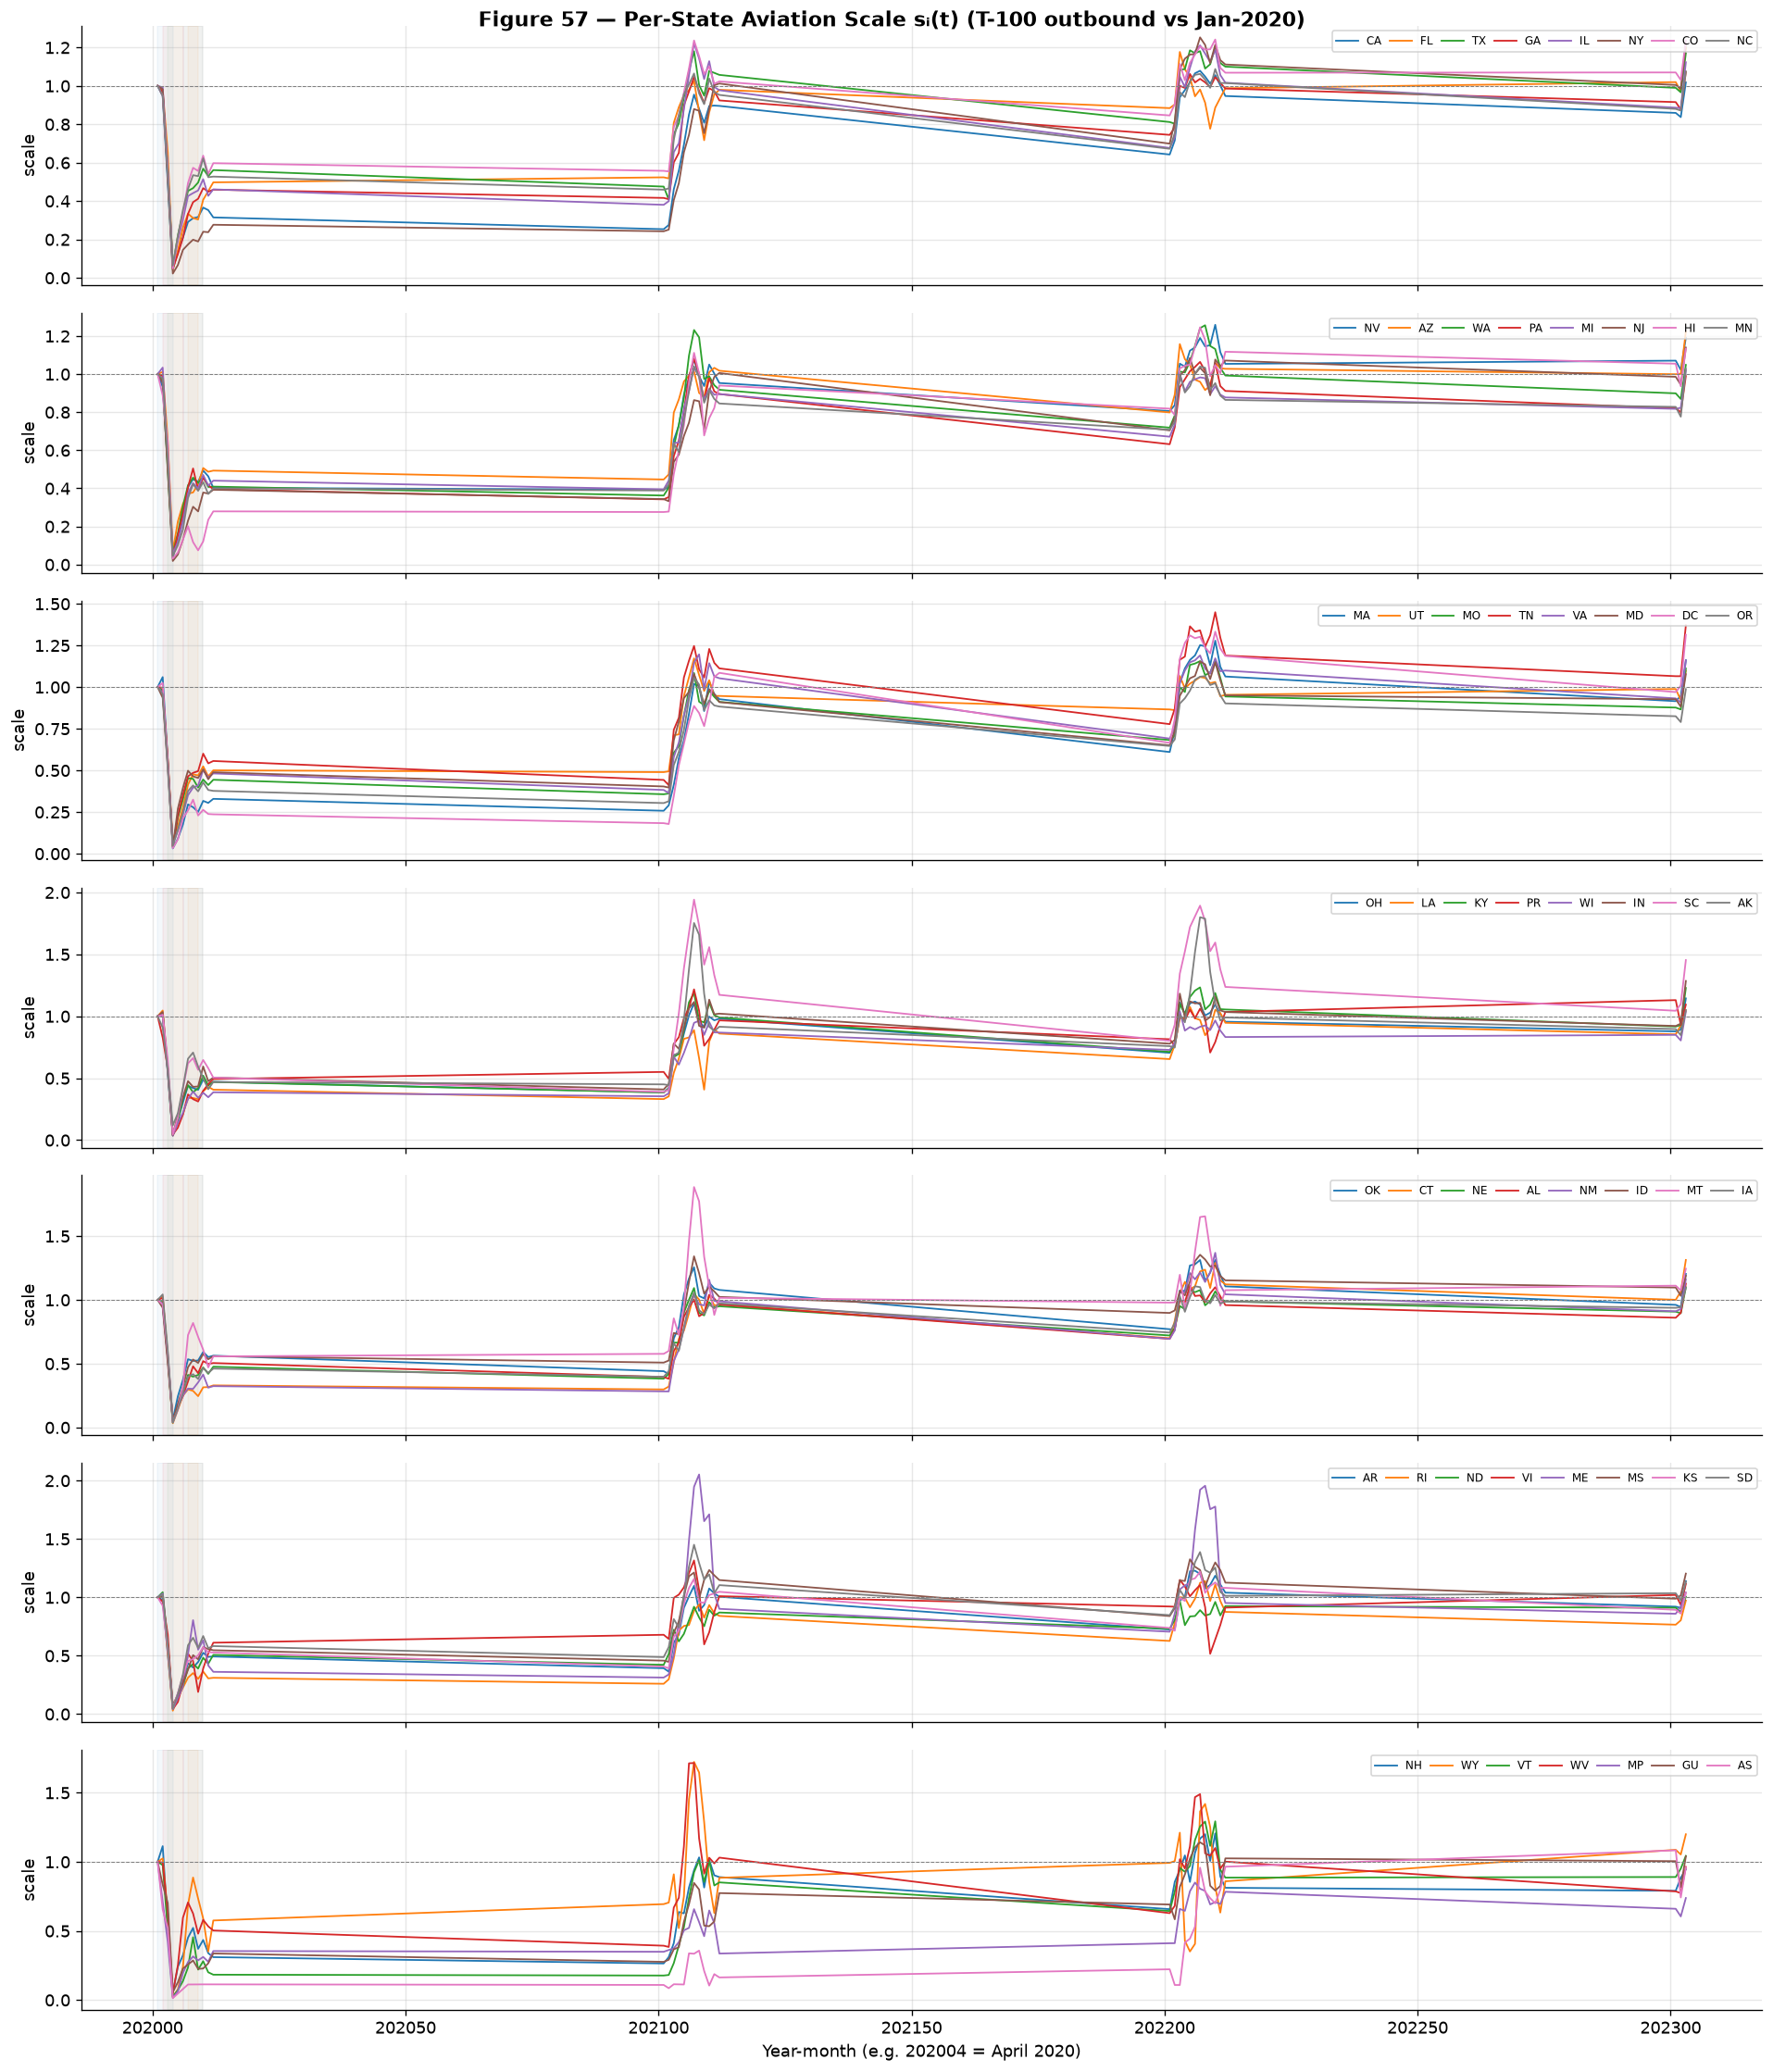

Figure 57 saved.


In [17]:
# ── Figure 57: per-state aviation scale (56 states, 7 panels × 8) ────────────
order = st[st.ym == 202001].sort_values('outbound', ascending=False).state.tolist()
fig, axes = plt.subplots(7, 1, figsize=(16, 19), sharex=True)
fig.suptitle('Figure 57 — Per-State Aviation Scale sᵢ(t) (T-100 outbound vs Jan-2020)',
             fontsize=13, fontweight='bold')
for p in range(7):
    ax = axes[p]
    for sname in order[p*8:(p+1)*8]:
        sub = st[st.state == sname].set_index(st[st.state == sname].ym)['scale_out']
        ax.plot(sub.index, sub.values, lw=1.1, label=sname)
    ax.axhline(1.0, color='gray', lw=0.6, ls='--')
    ax.set_ylabel('scale')
    ax.legend(fontsize=7, ncol=8, loc='upper right', columnspacing=0.8)
    for i, (wname, (ws, we)) in enumerate(US_WAVES.items()):
        ax.axvspan(202000 + int(ws[5:7]), 202000 + int(we[5:7]),
                   alpha=0.05, color=WAVE_COLORS[i])
axes[-1].set_xlabel('Year-month (e.g. 202004 = April 2020)')
plt.tight_layout()
plt.savefig('../assets/fig57_state_scale.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 57 saved.")

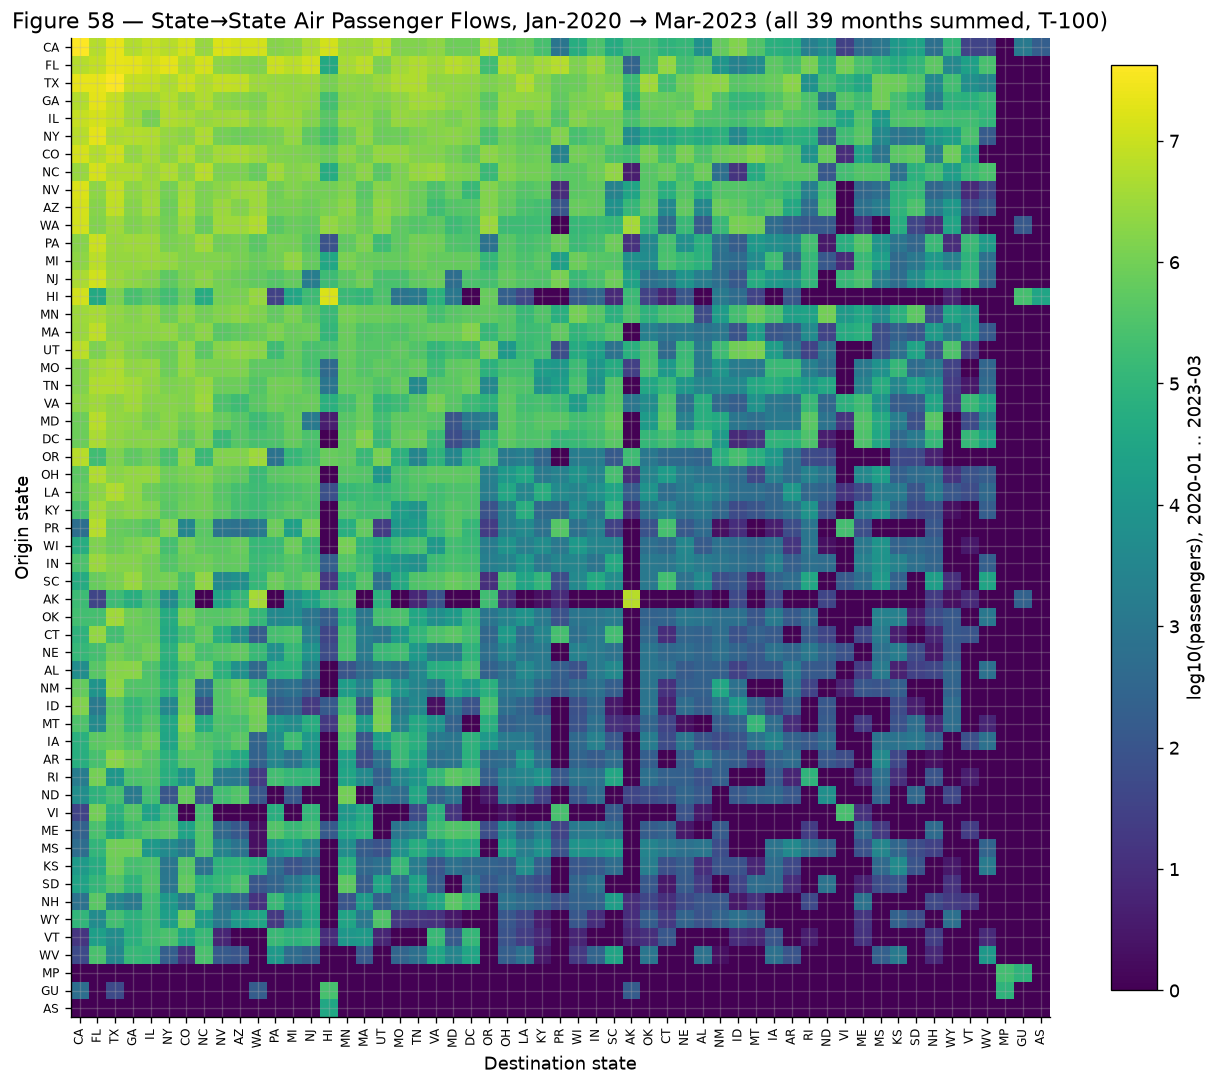

Figure 58 saved.


In [18]:
# ── Figure 58: state→state flow matrix (log passengers) ───────────────────────
import numpy as np
mat = pr.pivot_table(index='origin_state', columns='dest_state',
                     values='PASSENGERS', aggfunc='sum').reindex(
                         index=order, columns=order).fillna(0)
mat_log = np.log10(mat.values + 1)

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(mat_log, cmap='viridis')
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=7)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=7)
ax.set_xlabel('Destination state')
ax.set_ylabel('Origin state')
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('log10(passengers), 2020-01 .. 2023-03')
ax.set_title('Figure 58 — State→State Air Passenger Flows, '
             'Jan-2020 → Mar-2023 (all 39 months summed, T-100)')
plt.tight_layout()
plt.savefig('../assets/fig58_state_pairs.png', dpi=150, bbox_inches='tight')
plt.show()
print("Figure 58 saved.")

### Reading Figure 58 (time span & the diagonal)

The heatmap sums **all 39 months** (2020-01 → 2023-03) into a single
matrix, plotted on a **log10(passengers+1)** colour scale.

- The bright diagonal is *intra-state* traffic — the largest single flows
  in US domestic aviation are intra-state routes (LAX–SFO, SFO–SAN,
  DFW–IAH, DFW–AUS…): CA→CA = 41.9 M and TX→TX = 38.4 M passengers over
  the period are the two biggest cells of the table.  Across the whole
  matrix the diagonal is still only ≈ 7.7 % of total passengers — its
  visual dominance comes from the log scale, which dims most cross-state
  cells by orders of magnitude.
- The off-diagonal cells are **not symmetric**: A→B ≠ B→A in general
  (e.g. Apr-2020 NY→CA 6,308 vs CA→NY 4,891 passengers).  Summed over
  39 months the two directions nearly balance, because air travel is
  round-trip (TX→CA 22.4 M vs CA→TX 22.2 M), but they never match
  exactly.
